# Retail Store Sales Analysis: Customer & Purchase Behavior

## Business problem
The business wants to understand sales performance and customer purchasing patterns, identify data-quality issues, and develop evidence-based recommendations.

## Project objectives
- Inspect and clean the retail transaction data without inventing missing values.
- Analyse revenue, product/category performance, payment methods, locations, and monthly trends.
- Explore customer spending and repeat-month activity.
- Communicate findings with clear charts and practical recommendations.

## Important definitions
- **Transaction revenue:** `Total Spent`, using `Price Per Unit × Quantity` only when `Total Spent` is missing and both inputs are available.
- **Transaction count:** number of unique `Transaction ID` values.
- **Customer count:** number of unique `Customer ID` values.
- The dataset does not specify a currency in its column names, so monetary values are labelled as recorded amounts rather than assuming a currency.

> Run the notebook from top to bottom after placing `retail_store_sales.csv` in the same folder. Review the data-quality decisions and conclusions against the actual outputs before publishing.

# 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('retail_store_sales.csv')

# 2. Understand the dataset

# Check the size

In [3]:
df.shape

(12575, 11)

# Look at the data

In [4]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [5]:
df.tail()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True
12574,TXN_2407494,CUST_23,Food,Item_9_FOOD,17.0,3.0,51.0,Cash,Online,2022-08-06,NaN


# See the column names

In [6]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

# Check data types

In [7]:
df.dtypes

Transaction ID          str
Customer ID             str
Category                str
Item                    str
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
Discount Applied     object
dtype: object

## Dataset structure and completeness

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.9+ MB


## Check missing values

In [9]:
missing_count=df.isnull().sum()

# Check missing percentage

In [10]:
missing_percent=df.isnull().mean()*100
missing_percent

Transaction ID       0.000000
Customer ID          0.000000
Category             0.000000
Item                 9.646123
Price Per Unit       4.842942
Quantity             4.803181
Total Spent          4.803181
Payment Method       0.000000
Location             0.000000
Transaction Date     0.000000
Discount Applied    33.391650
dtype: float64

# Check duplicates

In [11]:
df.duplicated().sum()

np.int64(0)

# Understand numerical columns

In [12]:
df.describe()

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


# 3. Investigate data quality

In [13]:
miss_col=df.isnull().sum()

In [14]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [15]:
df[df['Item'].isnull()]

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
...,...,...,...,...,...,...,...,...,...,...,...
12527,TXN_1069238,CUST_23,Food,NaN,5.0,NaN,NaN,Digital Wallet,In-store,2022-08-13,False
12552,TXN_4823896,CUST_05,Milk Products,NaN,8.0,NaN,NaN,Cash,In-store,2022-07-21,False
12556,TXN_4397672,CUST_04,Beverages,NaN,41.0,NaN,NaN,Credit Card,Online,2024-11-28,True
12562,TXN_7422454,CUST_07,Butchers,NaN,33.5,NaN,NaN,Cash,Online,2023-04-15,NaN


In [16]:
missing_summary=pd.DataFrame(
    {'missing_count':missing_count,
     'missing_percent':missing_percent
    }
)     

In [17]:
missing_summary

,missing_count,missing_percent
Transaction ID,0,0.000000
Customer ID,0,0.000000
Category,0,0.000000
Item,1213,9.646123
Price Per Unit,609,4.842942
Quantity,604,4.803181
Total Spent,604,4.803181
Payment Method,0,0.000000
Location,0,0.000000
Transaction Date,0,0.000000


# Convert the transaction date to a datetime type

In [18]:
df.dtypes

Transaction ID          str
Customer ID             str
Category                str
Item                    str
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
Discount Applied     object
dtype: object

In [19]:
df['Transaction Date']=pd.to_datetime(df['Transaction Date'],errors='coerce')

In [20]:
df['Transaction Date']

0       2024-04-08
1       2023-07-23
2       2022-10-05
3       2022-05-07
4       2022-10-02
           ...    
12570   2023-09-03
12571   2022-08-12
12572   2024-08-24
12573   2023-12-30
12574   2022-08-06
Name: Transaction Date, Length: 12575, dtype: datetime64[us]

# Check suspicious numerical values

In [21]:
df.describe()

,Price Per Unit,Quantity,Total Spent,Transaction Date
count,11966.000000,11971.000000,11971.000000,12575
mean,23.365912,5.536380,129.652577,2023-07-12 20:23:41.105367
min,5.000000,1.000000,5.000000,2022-01-01 00:00:00
25%,14.000000,3.000000,51.000000,2022-09-30 00:00:00
50%,23.000000,6.000000,108.500000,2023-07-13 00:00:00
75%,33.500000,8.000000,192.000000,2024-04-24 00:00:00
max,41.000000,10.000000,410.000000,2025-01-18 00:00:00
std,10.743519,2.857883,94.750697,NaN


In [22]:
# Inspect ranges before deciding whether values are invalid.
# A large/small value is not automatically an error; interpret it in context.

# Missing Values
# First, identify columns with missing values

In [23]:
missing=df.isnull().sum()
missing[missing>0]

Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Discount Applied    4199
dtype: int64

# Find the actual missing rows

In [24]:
df[df['Item'].isnull()].head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN


# Show rows where at least one column has a missing value.

In [25]:
df[df.isnull().any(axis=1)]

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
14,TXN_2490363,CUST_09,Milk Products,Item_16_MILK,27.5,2.0,55.0,Digital Wallet,Online,2022-05-22,NaN
...,...,...,...,...,...,...,...,...,...,...,...
12564,TXN_2153066,CUST_17,Electric household essentials,NaN,29.0,NaN,NaN,Digital Wallet,In-store,2024-03-28,False
12568,TXN_1096134,CUST_06,Food,Item_4_FOOD,9.5,8.0,76.0,Digital Wallet,In-store,2022-06-11,NaN
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN


In [26]:
missing_summary

,missing_count,missing_percent
Transaction ID,0,0.000000
Customer ID,0,0.000000
Category,0,0.000000
Item,1213,9.646123
Price Per Unit,609,4.842942
Quantity,604,4.803181
Total Spent,604,4.803181
Payment Method,0,0.000000
Location,0,0.000000
Transaction Date,0,0.000000


In [27]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [28]:
# Compare the recorded transaction total with Price Per Unit × Quantity.
calculated_total = df['Price Per Unit'] * df['Quantity']
comparison = pd.DataFrame({
    'calculated_total': calculated_total,
    'recorded_total': df['Total Spent'],
    'difference': df['Total Spent'] - calculated_total
})
comparison.head(10)

,calculated_total,recorded_total,difference
0,185.0,185.0,0.0
1,261.0,261.0,0.0
2,43.0,43.0,0.0
3,247.5,247.5,0.0
4,87.5,87.5,0.0
5,NaN,200.0,NaN
6,40.0,40.0,0.0
7,NaN,NaN,NaN
8,27.5,27.5,0.0
9,109.5,109.5,0.0


# Recoverable Unit Price


In [29]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [30]:
recover_price=df[df['Price Per Unit'].isnull()&
df['Quantity'].notna()&
df['Total Spent'].notna()][['Price Per Unit','Quantity','Total Spent']]
recover_price

,Price Per Unit,Quantity,Total Spent
5,NaN,10.0,200.0
11,NaN,8.0,52.0
17,NaN,10.0,275.0
21,NaN,3.0,105.0
32,NaN,8.0,196.0
...,...,...,...
12435,NaN,5.0,32.5
12457,NaN,4.0,86.0
12477,NaN,4.0,80.0
12491,NaN,1.0,26.0


In [31]:
recover_total=df[df['Total Spent'].isnull()&
    df['Price Per Unit'].notna()&
df['Quantity'].notna()
][['Price Per Unit','Quantity','Total Spent']]
recover_total.head()

,Price Per Unit,Quantity,Total Spent


In [32]:
recover_quan=df[df['Total Spent'].notna()&
    df['Price Per Unit'].notna()&
df['Quantity'].isnull()
][['Price Per Unit','Quantity','Total Spent']]
recover_quan

,Price Per Unit,Quantity,Total Spent


In [33]:
recover_price

,Price Per Unit,Quantity,Total Spent
5,NaN,10.0,200.0
11,NaN,8.0,52.0
17,NaN,10.0,275.0
21,NaN,3.0,105.0
32,NaN,8.0,196.0
...,...,...,...
12435,NaN,5.0,32.5
12457,NaN,4.0,86.0
12477,NaN,4.0,80.0
12491,NaN,1.0,26.0


In [34]:
# A possible unit price can be derived only when the total and quantity are known.
# This is an audit column; it is not revenue.
df['Calculated Unit Price'] = df['Total Spent'] / df['Quantity'].replace(0, np.nan)
df[['Price Per Unit', 'Quantity', 'Total Spent', 'Calculated Unit Price']].head()

,Price Per Unit,Quantity,Total Spent,Calculated Unit Price
0,18.5,10.0,185.0,18.5
1,29.0,9.0,261.0,29.0
2,21.5,2.0,43.0,21.5
3,27.5,9.0,247.5,27.5
4,12.5,7.0,87.5,12.5


In [35]:
df[['Price Per Unit', 'Quantity', 'Total Spent', 'Calculated Unit Price']].head()

,Price Per Unit,Quantity,Total Spent,Calculated Unit Price
0,18.5,10.0,185.0,18.5
1,29.0,9.0,261.0,29.0
2,21.5,2.0,43.0,21.5
3,27.5,9.0,247.5,27.5
4,12.5,7.0,87.5,12.5


In [36]:
# Rows where a missing unit price could potentially be recovered from total / quantity.
df.loc[
    df['Price Per Unit'].isna() & df['Calculated Unit Price'].notna(),
    ['Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Calculated Unit Price']
].head(10)

,Item,Price Per Unit,Quantity,Total Spent,Calculated Unit Price
5,NaN,NaN,10.0,200.0,20.0
11,NaN,NaN,8.0,52.0,6.5
17,NaN,NaN,10.0,275.0,27.5
21,NaN,NaN,3.0,105.0,35.0
32,NaN,NaN,8.0,196.0,24.5
127,NaN,NaN,10.0,275.0,27.5
159,NaN,NaN,9.0,126.0,14.0
216,NaN,NaN,8.0,40.0,5.0
247,NaN,NaN,7.0,150.5,21.5
271,NaN,NaN,9.0,99.0,11.0


In [37]:
# verify the rows 

In [38]:
# Check whether the recorded total is consistent with unit price × quantity.
complete = df.loc[
    df[['Price Per Unit', 'Quantity', 'Total Spent']].notna().all(axis=1),
    ['Price Per Unit', 'Quantity', 'Total Spent']
].copy()
complete['Calculated Total'] = complete['Price Per Unit'] * complete['Quantity']
complete['Difference'] = complete['Total Spent'] - complete['Calculated Total']
complete.head(10)

,Price Per Unit,Quantity,Total Spent,Calculated Total,Difference
0,18.5,10.0,185.0,185.0,0.0
1,29.0,9.0,261.0,261.0,0.0
2,21.5,2.0,43.0,43.0,0.0
3,27.5,9.0,247.5,247.5,0.0
4,12.5,7.0,87.5,87.5,0.0
6,5.0,8.0,40.0,40.0,0.0
8,27.5,1.0,27.5,27.5,0.0
9,36.5,3.0,109.5,109.5,0.0
10,8.0,9.0,72.0,72.0,0.0
12,6.5,7.0,45.5,45.5,0.0


In [39]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price'],
      dtype='str')

In [40]:
# Inspect rows with missing unit price. Item names alone are not enough to infer a price.
price_cal = df.loc[
    df['Price Per Unit'].isna(),
    ['Item', 'Price Per Unit', 'Quantity', 'Total Spent']
]
price_cal.head(10)

,Item,Price Per Unit,Quantity,Total Spent
5,NaN,NaN,10.0,200.0
11,NaN,NaN,8.0,52.0
17,NaN,NaN,10.0,275.0
21,NaN,NaN,3.0,105.0
32,NaN,NaN,8.0,196.0
127,NaN,NaN,10.0,275.0
159,NaN,NaN,9.0,126.0
216,NaN,NaN,8.0,40.0
247,NaN,NaN,7.0,150.5
271,NaN,NaN,9.0,99.0


In [41]:
# Recover unit price only where Total Spent and a non-zero Quantity are available.
# Keep unrecoverable values missing; do not guess prices from item names.
df['Price Per Unit'] = df['Price Per Unit'].fillna(
    df['Total Spent'] / df['Quantity'].replace(0, np.nan)
)

# Create transaction revenue. Use the recorded total when available; otherwise
# calculate it only when both unit price and quantity are available.
df['Revenue'] = df['Total Spent'].fillna(df['Price Per Unit'] * df['Quantity'])

print('Missing unit prices after recoverable fills:', df['Price Per Unit'].isna().sum())
print('Missing revenue after recoverable calculation:', df['Revenue'].isna().sum())

Missing unit prices after recoverable fills: 0
Missing revenue after recoverable calculation: 604


In [42]:
df[['Price Per Unit', 'Quantity', 'Total Spent', 'Revenue']].head()

,Price Per Unit,Quantity,Total Spent,Revenue
0,18.5,10.0,185.0,185.0
1,29.0,9.0,261.0,261.0
2,21.5,2.0,43.0,43.0
3,27.5,9.0,247.5,247.5
4,12.5,7.0,87.5,87.5


In [43]:
df['Price Per Unit'].isna().sum()

np.int64(0)

In [44]:
# Rows where both quantity and total are missing cannot be reconstructed from these fields alone.
check = df.loc[
    df['Quantity'].isna() & df['Total Spent'].isna(),
    ['Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Revenue']
]
check.head()

,Item,Price Per Unit,Quantity,Total Spent,Revenue
7,NaN,33.5,NaN,NaN,NaN
15,NaN,24.5,NaN,NaN,NaN
19,NaN,35.0,NaN,NaN,NaN
25,NaN,39.5,NaN,NaN,NaN
34,NaN,23.0,NaN,NaN,NaN


In [45]:
len(check)

604

In [46]:
check.isna().sum()

Item              604
Price Per Unit      0
Quantity          604
Total Spent       604
Revenue           604
dtype: int64

In [47]:
# duplicates cleaning

In [48]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [49]:
# Check full-row duplicates before dropping anything.
df.duplicated().sum()

np.int64(0)

In [50]:
# Check whether the proposed transaction/customer key repeats. Repeated customers are expected; transaction IDs should be investigated separately.
df['Transaction ID'].duplicated().sum()

np.int64(0)

In [51]:
df.loc[df['Transaction ID'].duplicated(keep=False)].sort_values('Transaction ID').head(20)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Calculated Unit Price,Revenue


In [52]:
# Do not drop rows based only on Transaction ID + Customer ID without checking whether
# the repeated records are genuine duplicates. This cell intentionally does not alter df.

# Check data types

In [53]:
df.dtypes

Transaction ID                      str
Customer ID                         str
Category                            str
Item                                str
Price Per Unit                  float64
Quantity                        float64
Total Spent                     float64
Payment Method                      str
Location                            str
Transaction Date         datetime64[us]
Discount Applied                 object
Calculated Unit Price           float64
Revenue                         float64
dtype: object

# basic cleaning

In [54]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [55]:
df[['Price Per Unit','Quantity','Total Spent']].describe()

,Price Per Unit,Quantity,Total Spent
count,12575.000000,11971.000000,11971.000000
mean,23.369304,5.536380,129.652577
std,10.748728,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


In [56]:
# Investigate negative, zero, or extreme values in context. Do not remove outliers automatically.
# A valid bulk purchase can be large, and the IQR rule flags unusual values rather than proving errors.

# statistics

In [57]:
# descriptive statistic
df.describe()

,Price Per Unit,Quantity,Total Spent,Transaction Date,Calculated Unit Price,Revenue
count,12575.000000,11971.000000,11971.000000,12575,11971.000000,11971.000000
mean,23.369304,5.536380,129.652577,2023-07-12 20:23:41.105367,23.360872,129.652577
min,5.000000,1.000000,5.000000,2022-01-01 00:00:00,5.000000,5.000000
25%,14.000000,3.000000,51.000000,2022-09-30 00:00:00,14.000000,51.000000
50%,23.000000,6.000000,108.500000,2023-07-13 00:00:00,23.000000,108.500000
75%,33.500000,8.000000,192.000000,2024-04-24 00:00:00,33.500000,192.000000
max,41.000000,10.000000,410.000000,2025-01-18 00:00:00,41.000000,410.000000
std,10.748728,2.857883,94.750697,NaN,10.741889,94.750697


In [58]:
# mean
df['Total Spent'].mean()

np.float64(129.6525770612313)

In [59]:
#median
df['Total Spent'].median()

np.float64(108.5)

In [60]:
#investigate mean and median

In [61]:
# Mode(s) of the payment method. This identifies the most frequent recorded category.
df['Payment Method'].mode()

0    Cash
Name: Payment Method, dtype: str

# Quartle- how the transaction values are distributed

In [62]:
df['Total Spent'].quantile([0.25,0.5,0.75])

0.25     51.0
0.50    108.5
0.75    192.0
Name: Total Spent, dtype: float64

In [63]:
q1=df['Total Spent'].quantile(0.25)
q3=df['Total Spent'].quantile(0.75)
iqr=q3-q1
iqr

np.float64(141.0)

In [64]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print('Lower IQR fence:', lower)
print('Upper IQR fence:', upper)

Lower IQR fence: -160.5
Upper IQR fence: 403.5


In [65]:
outliers = df.loc[df['Total Spent'].notna() & ((df['Total Spent'] < lower) | (df['Total Spent'] > upper))]
outliers

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Calculated Unit Price,Revenue
27,TXN_1599706,CUST_14,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2024-03-24,True,41.0,410.0
133,TXN_2953434,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2023-08-10,NaN,41.0,410.0
339,TXN_4374445,CUST_12,Food,Item_25_FOOD,41.0,10.0,410.0,Digital Wallet,Online,2024-10-17,NaN,41.0,410.0
869,TXN_1814138,CUST_06,Beverages,Item_25_BEV,41.0,10.0,410.0,Credit Card,In-store,2024-11-16,NaN,41.0,410.0
1060,TXN_3710081,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,In-store,2023-08-12,NaN,41.0,410.0
1088,TXN_1273334,CUST_22,Beverages,Item_25_BEV,41.0,10.0,410.0,Digital Wallet,In-store,2022-11-04,True,41.0,410.0
1468,TXN_1938135,CUST_17,Butchers,Item_25_BUT,41.0,10.0,410.0,Digital Wallet,In-store,2023-12-20,True,41.0,410.0
1505,TXN_8520397,CUST_12,Electric household essentials,Item_25_EHE,41.0,10.0,410.0,Credit Card,Online,2024-03-27,True,41.0,410.0
1568,TXN_8048041,CUST_14,Butchers,Item_25_BUT,41.0,10.0,410.0,Credit Card,In-store,2023-12-25,True,41.0,410.0
1950,TXN_1860120,CUST_01,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,Online,2022-01-19,True,41.0,410.0


# understand why the outlier high

In [66]:
outliers.sort_values('Total Spent',ascending=False).head(10)#max quantity* max price so it assign as a max outlier

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Calculated Unit Price,Revenue
27,TXN_1599706,CUST_14,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2024-03-24,True,41.0,410.0
133,TXN_2953434,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2023-08-10,NaN,41.0,410.0
339,TXN_4374445,CUST_12,Food,Item_25_FOOD,41.0,10.0,410.0,Digital Wallet,Online,2024-10-17,NaN,41.0,410.0
869,TXN_1814138,CUST_06,Beverages,Item_25_BEV,41.0,10.0,410.0,Credit Card,In-store,2024-11-16,NaN,41.0,410.0
1060,TXN_3710081,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,In-store,2023-08-12,NaN,41.0,410.0
1088,TXN_1273334,CUST_22,Beverages,Item_25_BEV,41.0,10.0,410.0,Digital Wallet,In-store,2022-11-04,True,41.0,410.0
1468,TXN_1938135,CUST_17,Butchers,Item_25_BUT,41.0,10.0,410.0,Digital Wallet,In-store,2023-12-20,True,41.0,410.0
1505,TXN_8520397,CUST_12,Electric household essentials,Item_25_EHE,41.0,10.0,410.0,Credit Card,Online,2024-03-27,True,41.0,410.0
1568,TXN_8048041,CUST_14,Butchers,Item_25_BUT,41.0,10.0,410.0,Credit Card,In-store,2023-12-25,True,41.0,410.0
1950,TXN_1860120,CUST_01,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,Online,2022-01-19,True,41.0,410.0


In [67]:
outliers.sort_values('Total Spent').head(10)#min quantity* min price so it assign as a min outlier

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Calculated Unit Price,Revenue
27,TXN_1599706,CUST_14,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2024-03-24,True,41.0,410.0
133,TXN_2953434,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2023-08-10,NaN,41.0,410.0
339,TXN_4374445,CUST_12,Food,Item_25_FOOD,41.0,10.0,410.0,Digital Wallet,Online,2024-10-17,NaN,41.0,410.0
869,TXN_1814138,CUST_06,Beverages,Item_25_BEV,41.0,10.0,410.0,Credit Card,In-store,2024-11-16,NaN,41.0,410.0
1060,TXN_3710081,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,In-store,2023-08-12,NaN,41.0,410.0
1088,TXN_1273334,CUST_22,Beverages,Item_25_BEV,41.0,10.0,410.0,Digital Wallet,In-store,2022-11-04,True,41.0,410.0
1468,TXN_1938135,CUST_17,Butchers,Item_25_BUT,41.0,10.0,410.0,Digital Wallet,In-store,2023-12-20,True,41.0,410.0
1505,TXN_8520397,CUST_12,Electric household essentials,Item_25_EHE,41.0,10.0,410.0,Credit Card,Online,2024-03-27,True,41.0,410.0
1568,TXN_8048041,CUST_14,Butchers,Item_25_BUT,41.0,10.0,410.0,Credit Card,In-store,2023-12-25,True,41.0,410.0
1950,TXN_1860120,CUST_01,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,Online,2022-01-19,True,41.0,410.0


# Univariate Numerical analysis

# check the distribution with a histogram

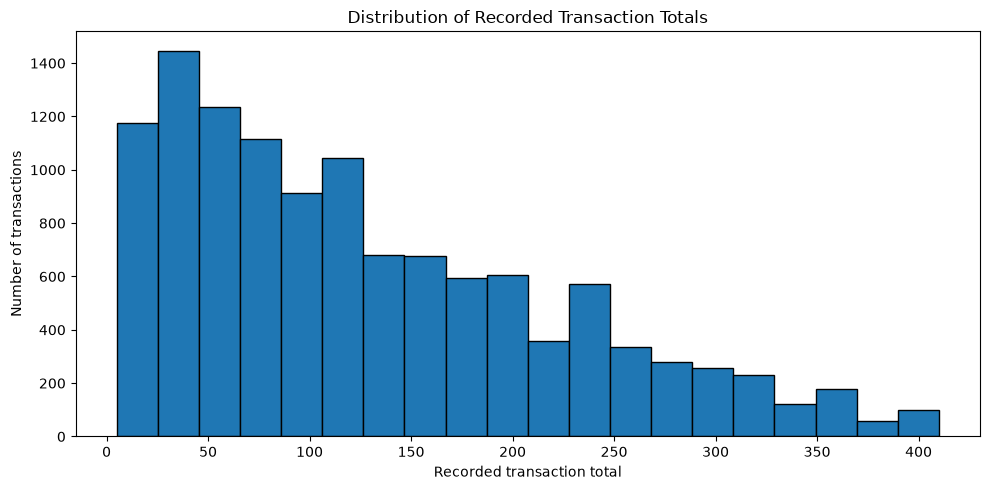

In [68]:
plt.figure(figsize=(10, 5))
plt.hist(df['Total Spent'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Recorded transaction total')
plt.ylabel('Number of transactions')
plt.title('Distribution of Recorded Transaction Totals')
plt.tight_layout()
plt.show()

# Boxplot 

C:\Users\Muspira\AppData\Local\Temp\ipykernel_8252\386833026.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['Total Spent'].dropna(), vert=False)


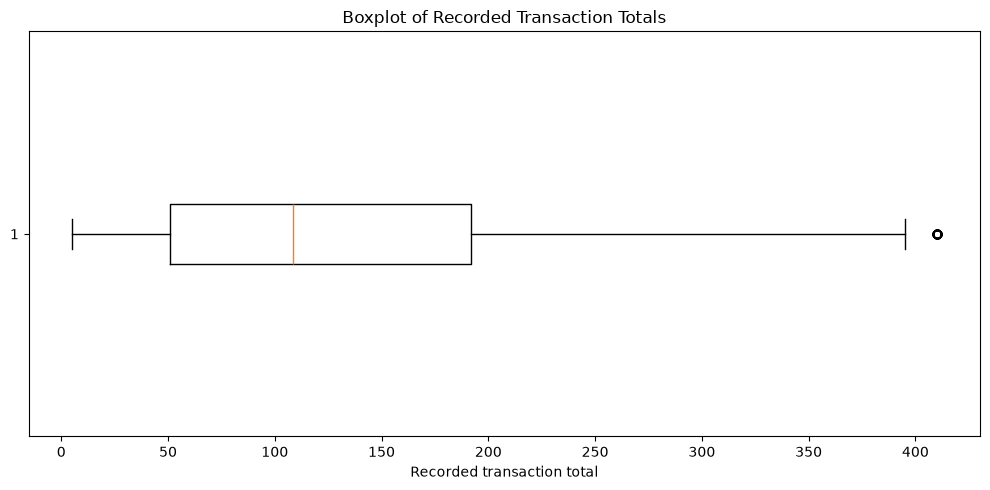

In [69]:
plt.figure(figsize=(10, 5))
plt.boxplot(df['Total Spent'].dropna(), vert=False)
plt.xlabel('Recorded transaction total')
plt.title('Boxplot of Recorded Transaction Totals')
plt.tight_layout()
plt.show()

# Univariate categorical analysis

# Bar chart

In [70]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

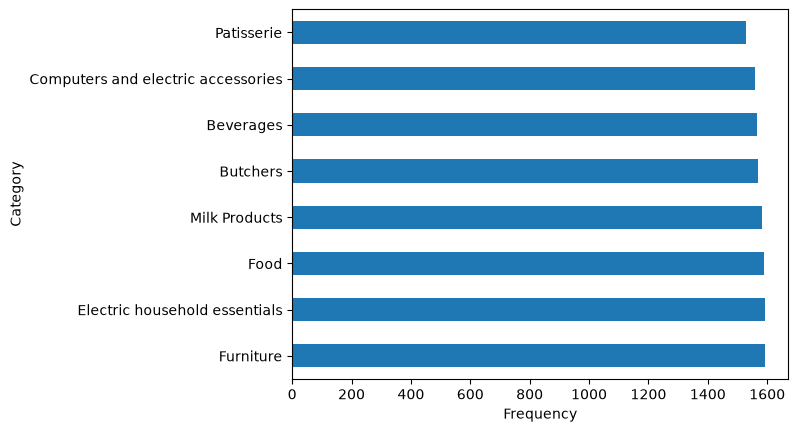

In [71]:
df['Category'].value_counts().plot(kind='barh')

plt.xlabel('Frequency')

plt.show()

# category vs. numerical
# category vs revenue

In [72]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [73]:
df.groupby('Category')['Revenue'].sum(min_count=1).sort_values(ascending=False)

Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Revenue, dtype: float64

# visualize

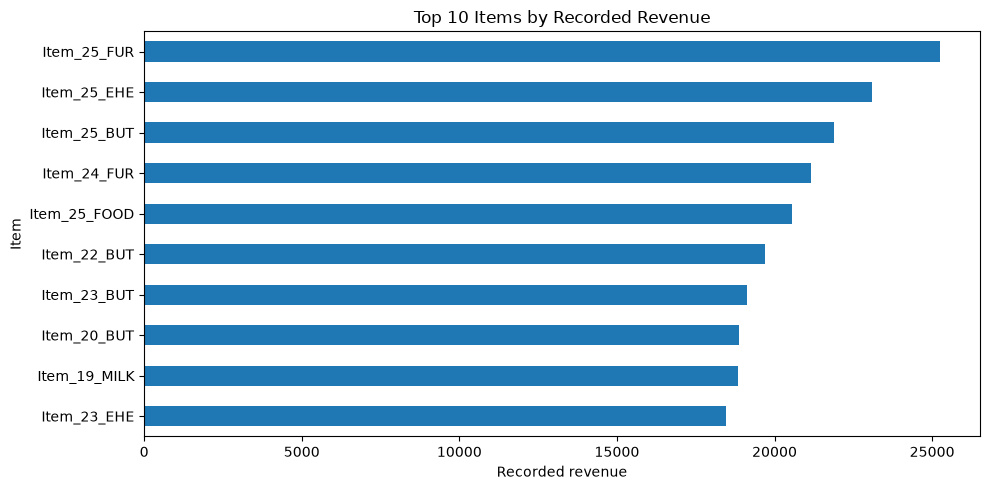

In [74]:
top_items_revenue = df.groupby('Item')['Revenue'].sum(min_count=1).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_items_revenue.sort_values().plot(kind='barh')
plt.xlabel('Recorded revenue')
plt.ylabel('Item')
plt.title('Top 10 Items by Recorded Revenue')
plt.tight_layout()
plt.show()

# Which product are purchased more often

In [75]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [76]:
df.groupby('Item')['Quantity'].sum(min_count=1).sort_values(ascending=False).head(10)

Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64

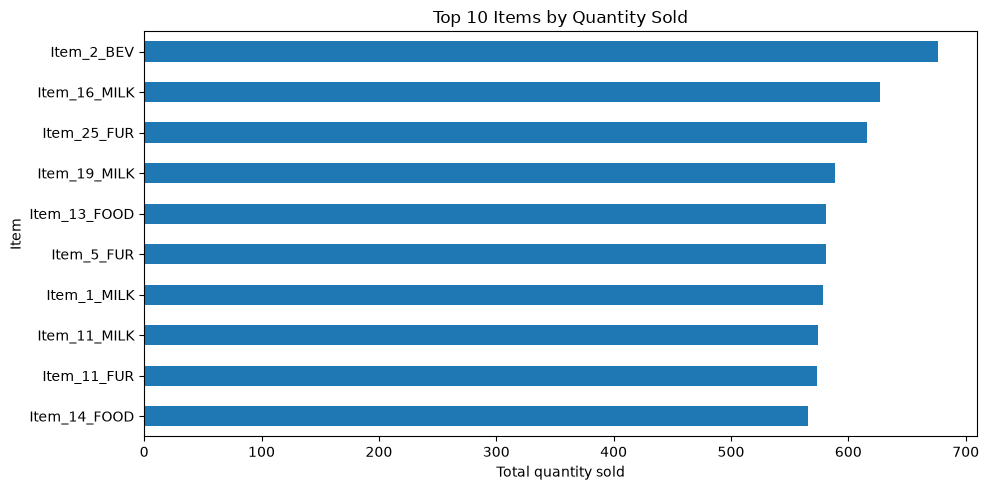

In [77]:
top_items_quantity = df.groupby('Item')['Quantity'].sum(min_count=1).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_items_quantity.sort_values().plot(kind='barh')
plt.xlabel('Total quantity sold')
plt.ylabel('Item')
plt.title('Top 10 Items by Quantity Sold')
plt.tight_layout()
plt.show()

# customer analyze

In [78]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [79]:
# Top customers by recorded revenue

In [80]:
df.groupby('Customer ID')['Revenue'].sum(min_count=1).sort_values(ascending=False).head(10)

Customer ID
CUST_24    68452.0
CUST_08    67351.5
CUST_05    66974.5
CUST_16    65570.5
CUST_13    65037.0
CUST_23    64507.0
CUST_10    63155.5
CUST_15    63117.5
CUST_21    62933.0
CUST_02    62046.5
Name: Revenue, dtype: float64

# visualize

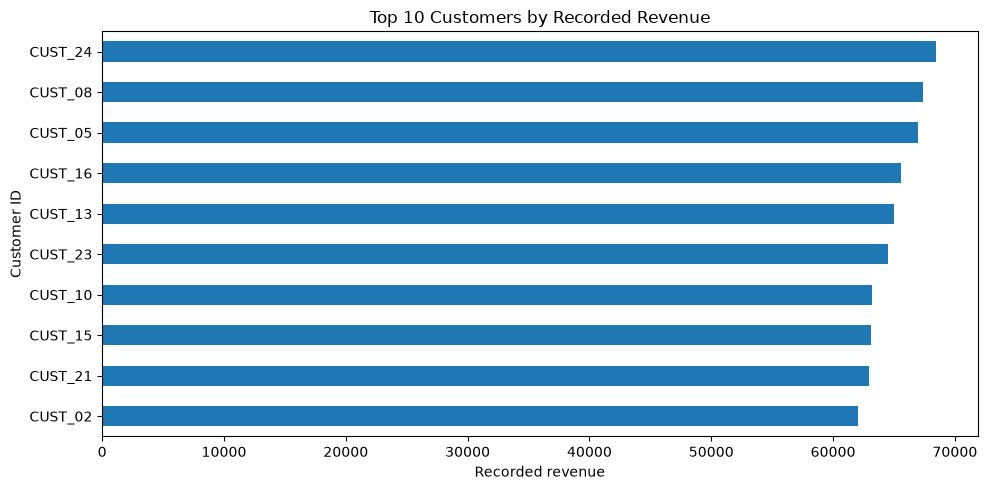

In [81]:
cust_rev_top = df.groupby('Customer ID')['Revenue'].sum(min_count=1).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
cust_rev_top.sort_values().plot(kind='barh')
plt.xlabel('Recorded revenue')
plt.ylabel('Customer ID')
plt.title('Top 10 Customers by Recorded Revenue')
plt.tight_layout()
plt.show()

# Customer Average Spending

In [82]:
avg_cust = df.groupby('Customer ID')['Revenue'].mean().sort_values(ascending=False).head(10)

# Analyse

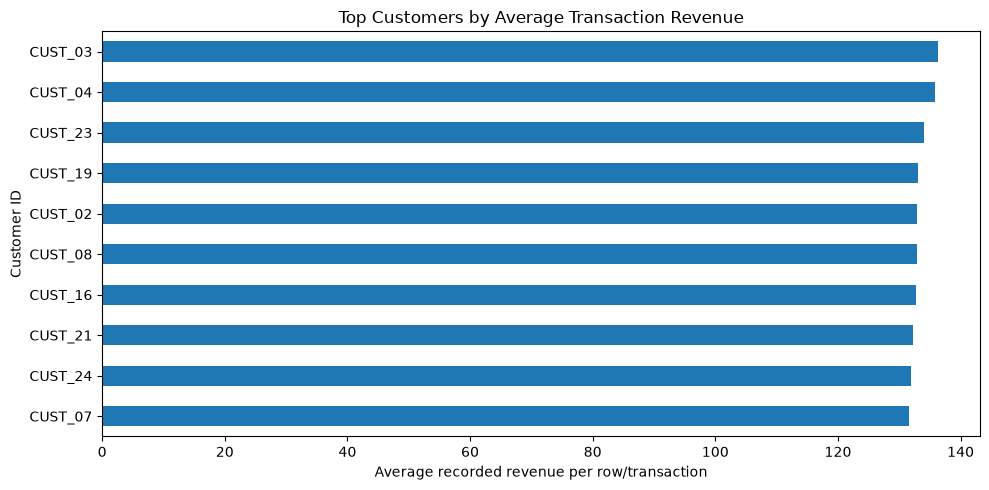

In [83]:
avg_cust = df.groupby('Customer ID')['Revenue'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
avg_cust.sort_values().plot(kind='barh')
plt.xlabel('Average recorded revenue per row/transaction')
plt.ylabel('Customer ID')
plt.title('Top Customers by Average Transaction Revenue')
plt.tight_layout()
plt.show()

# simple customer behaviour profile
# how frequently does each  customer purchase

In [84]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

# How frequency does each customer purchase

In [85]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Calculated Unit Price,Revenue
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True,18.5,185.0
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True,29.0,261.0
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False,21.5,43.0
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN,27.5,247.5
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False,12.5,87.5


In [86]:
customer_frequency = df.groupby('Customer ID')['Transaction ID'].nunique().sort_values(ascending=False).head(10)
customer_frequency

Customer ID
CUST_05    544
CUST_24    543
CUST_13    534
CUST_08    533
CUST_09    519
CUST_15    519
CUST_16    515
CUST_23    513
CUST_01    507
CUST_20    507
Name: Transaction ID, dtype: int64

# visualize

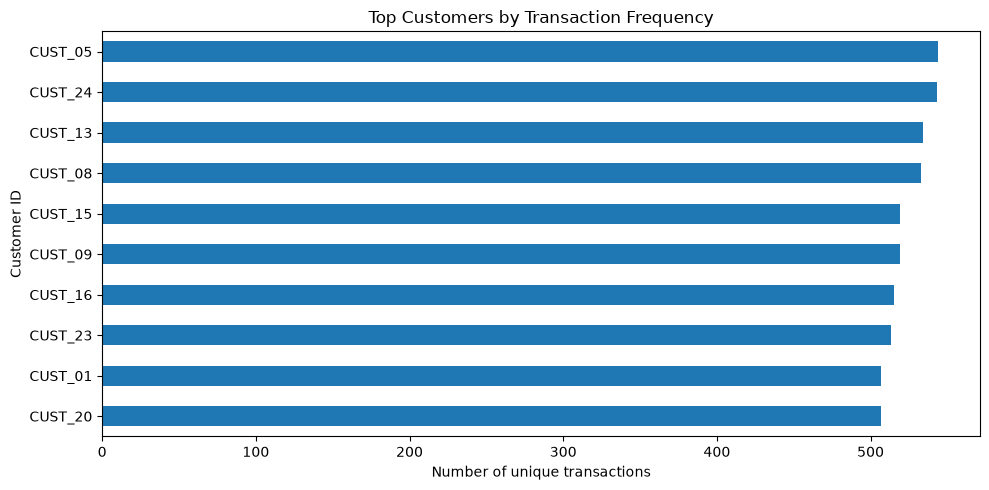

In [87]:
plt.figure(figsize=(10, 5))
customer_frequency.sort_values().plot(kind='barh')
plt.xlabel('Number of unique transactions')
plt.ylabel('Customer ID')
plt.title('Top Customers by Transaction Frequency')
plt.tight_layout()
plt.show()

# customer segmentation

In [88]:
# Build a consistent summary for every customer (do not combine separate top-N lists by index).
customer_summary = df.groupby('Customer ID').agg(
    Total_Revenue=('Revenue', lambda s: s.sum(min_count=1)),
    Average_Revenue=('Revenue', 'mean'),
    Frequency=('Transaction ID', 'nunique')
)
customer_summary.sort_values('Total_Revenue', ascending=False).head()

,Total_Revenue,Average_Revenue,Frequency
Customer ID,,,
CUST_24,68452.0,131.892100,543
CUST_08,67351.5,132.843195,533
CUST_05,66974.5,129.795543,544
CUST_16,65570.5,132.733806,515
CUST_13,65037.0,128.025591,534


In [89]:
customer_summary.sort_values('Total_Revenue', ascending=False).head()

,Total_Revenue,Average_Revenue,Frequency
Customer ID,,,
CUST_24,68452.0,131.892100,543
CUST_08,67351.5,132.843195,533
CUST_05,66974.5,129.795543,544
CUST_16,65570.5,132.733806,515
CUST_13,65037.0,128.025591,534


In [90]:
# check missing values
customer_summary[customer_summary.isna().any(axis=1)]

,Total_Revenue,Average_Revenue,Frequency
Customer ID,,,


In [91]:
customer_summary = df.groupby('Customer ID').agg(
    Total_Revenue=('Revenue', lambda s: s.sum(min_count=1)),
    Average_Revenue=('Revenue', 'mean'),
    Frequency=('Transaction ID', 'nunique')
)

In [92]:
customer_summary.sort_values(by='Total_Revenue',ascending=False).head()

,Total_Revenue,Average_Revenue,Frequency
Customer ID,,,
CUST_24,68452.0,131.892100,543
CUST_08,67351.5,132.843195,533
CUST_05,66974.5,129.795543,544
CUST_16,65570.5,132.733806,515
CUST_13,65037.0,128.025591,534


# Segment Customers by Revenue

In [93]:
# Calcudflate revenue thresholds
q1=customer_summary['Total_Revenue'].quantile(0.25)
q3=customer_summary['Total_Revenue'].quantile(0.75)
q3

np.float64(63155.5)

In [94]:
import numpy as np
customer_summary['customer_segment']=np.select(
[
customer_summary['Total_Revenue']<=q1,
(customer_summary['Total_Revenue']>q1)&(customer_summary['Total_Revenue']<=q3),
customer_summary['Total_Revenue']>q3
],
[
'lower_level_customer',
'middle_level_customer',
'high_level_customer',
],
    default='unknown'
)

In [95]:
customer_summary.sort_values(by='Total_Revenue',ascending=False).head()

,Total_Revenue,Average_Revenue,Frequency,customer_segment
Customer ID,,,,
CUST_24,68452.0,131.892100,543,high_level_customer
CUST_08,67351.5,132.843195,533,high_level_customer
CUST_05,66974.5,129.795543,544,high_level_customer
CUST_16,65570.5,132.733806,515,high_level_customer
CUST_13,65037.0,128.025591,534,high_level_customer


In [96]:
customer_summary['customer_segment'].value_counts(normalize=True).mul(100).round(2)

customer_segment
middle_level_customer    48.0
lower_level_customer     28.0
high_level_customer      24.0
Name: proportion, dtype: float64

# Analyze

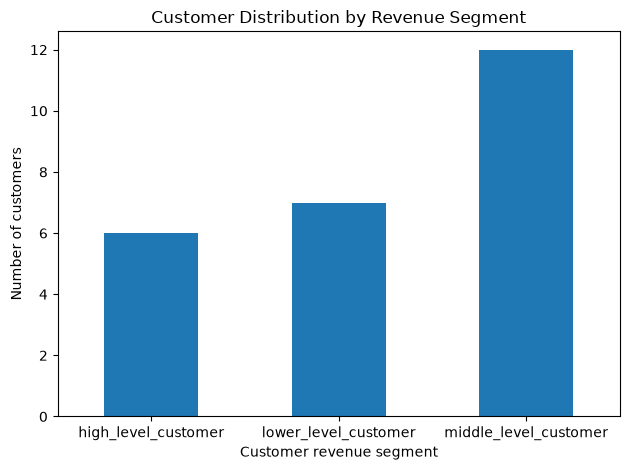

In [97]:
customer_summary['customer_segment'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Customer revenue segment')
plt.ylabel('Number of customers')
plt.title('Customer Distribution by Revenue Segment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# revenue contribution by customer segment

In [98]:
customer_summary.columns

Index(['Total_Revenue', 'Average_Revenue', 'Frequency', 'customer_segment'], dtype='str')

In [99]:
cust_seg_rev = customer_summary.groupby('customer_segment')['Total_Revenue'].sum(min_count=1).sort_values(ascending=False)
cust_seg_rev

customer_segment
middle_level_customer    741410.0
lower_level_customer     412768.5
high_level_customer      397892.5
Name: Total_Revenue, dtype: float64

In [100]:
cust_seg_rev

customer_segment
middle_level_customer    741410.0
lower_level_customer     412768.5
high_level_customer      397892.5
Name: Total_Revenue, dtype: float64

# visualize

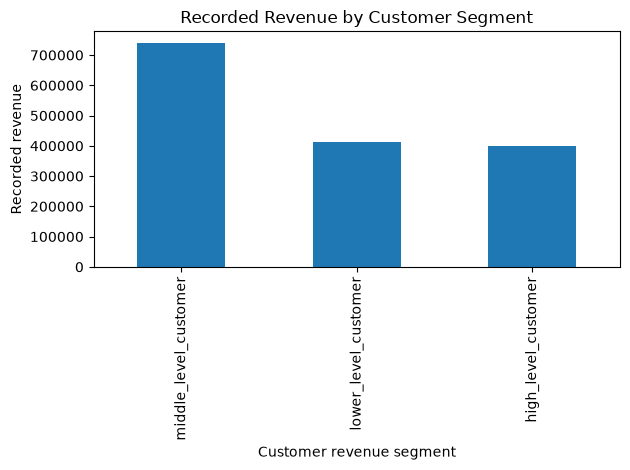

In [101]:
cust_seg_rev.plot(kind='bar')
plt.xlabel('Customer revenue segment')
plt.ylabel('Recorded revenue')
plt.title('Recorded Revenue by Customer Segment')
plt.tight_layout()
plt.show()

# retail custmer and purchase behavoiur analysis
## Payment Method analysis

In [102]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [103]:
cust_pay_method=df['Payment Method'].value_counts().sort_values(ascending=False).head()
cust_pay_method

Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

# visualize high frequency payment method

<Axes: xlabel='Payment Method'>

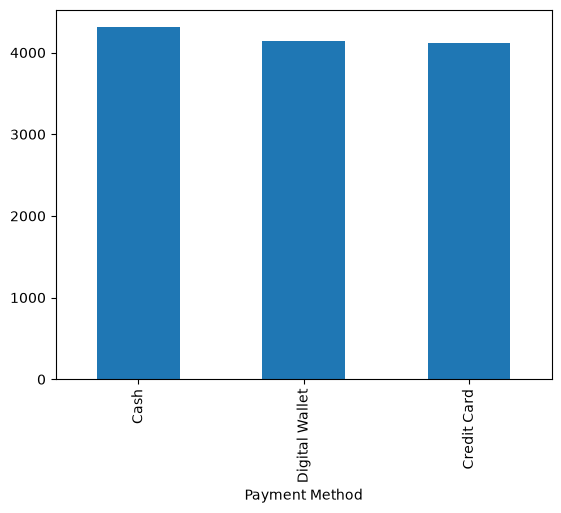

In [104]:
cust_pay_method.plot(kind='bar')

In [105]:
pay_highrev=df.groupby('Payment Method')['Revenue'].sum().sort_values(ascending=False).head()
pay_highrev

Payment Method
Cash              537710.0
Digital Wallet    507279.0
Credit Card       507082.0
Name: Revenue, dtype: float64

# which payment method produce high revenue

<Axes: xlabel='Payment Method'>

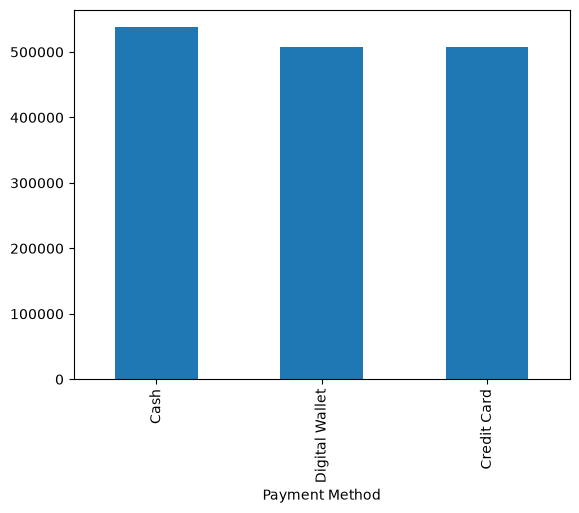

In [106]:
pay_highrev.plot(kind='bar')

In [107]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [108]:
payment_analysis = df.groupby('Payment Method').agg(
    Transaction_count=('Transaction ID', 'nunique'),
    Total_rev=('Revenue', lambda s: s.sum(min_count=1)),
    Avg_rev=('Revenue', 'mean')
).sort_values('Total_rev', ascending=False)
payment_analysis

,Transaction_count,Total_rev,Avg_rev
Payment Method,,,
Cash,4310,537710.0,131.052888
Digital Wallet,4144,507279.0,128.718346
Credit Card,4121,507082.0,129.127069


# Analyze sales by location
## which location generate the most revenue for the business

In [109]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue'],
      dtype='str')

In [110]:
loc_rev = df.groupby('Location')['Revenue'].sum(min_count=1).sort_values(ascending=False)
loc_rev

Location
Online      791401.0
In-store    760670.0
Name: Revenue, dtype: float64

# visualize

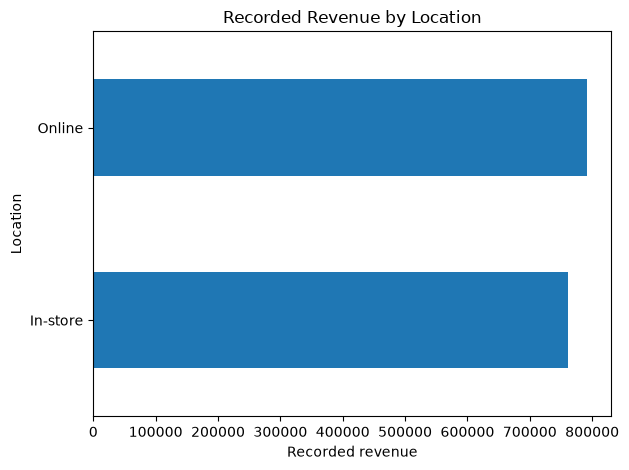

In [111]:
loc_rev.sort_values().plot(kind='barh')
plt.xlabel('Recorded revenue')
plt.ylabel('Location')
plt.title('Recorded Revenue by Location')
plt.tight_layout()
plt.show()

In [112]:
# compare transaction counts
loc_transaction=df.groupby('Location')['Transaction ID'].nunique()
loc_transaction

Location
In-store    6221
Online      6354
Name: Transaction ID, dtype: int64

# Location Analysis

In [113]:
location_analysis = pd.concat([
    loc_rev.rename('Revenue'),
    df.groupby('Location')['Transaction ID'].nunique().rename('Transactions')
], axis=1).sort_values('Revenue', ascending=False)
location_analysis

,Revenue,Transactions
Location,,
Online,791401.0,6354
In-store,760670.0,6221


In [114]:
location_analysis

,Revenue,Transactions
Location,,
Online,791401.0,6354
In-store,760670.0,6221


# Monthly Revenue Analysis

In [115]:
# check datatype
df.dtypes

Transaction ID                      str
Customer ID                         str
Category                            str
Item                                str
Price Per Unit                  float64
Quantity                        float64
Total Spent                     float64
Payment Method                      str
Location                            str
Transaction Date         datetime64[us]
Discount Applied                 object
Calculated Unit Price           float64
Revenue                         float64
dtype: object

In [116]:
#extract year and month
df['year_month']=df['Transaction Date'].dt.to_period('M')
df['year_month']

0        2024-04
1        2023-07
2        2022-10
3        2022-05
4        2022-10
          ...   
12570    2023-09
12571    2022-08
12572    2024-08
12573    2023-12
12574    2022-08
Name: year_month, Length: 12575, dtype: period[M]

In [117]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [118]:
month_rev = df.groupby('year_month')['Revenue'].sum(min_count=1).sort_index()

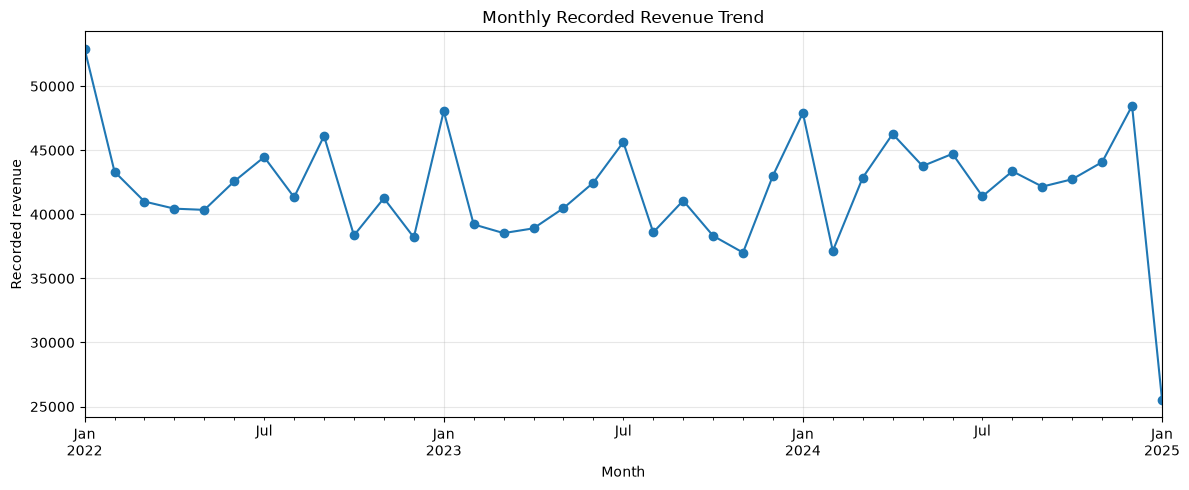

In [119]:
month_rev.plot(figsize=(12, 5), marker='o')
plt.xlabel('Month')
plt.ylabel('Recorded revenue')
plt.title('Monthly Recorded Revenue Trend')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [120]:
# Monthly Volume transaction
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [121]:
mon_transaction = df.groupby('year_month')['Transaction ID'].nunique().sort_index()

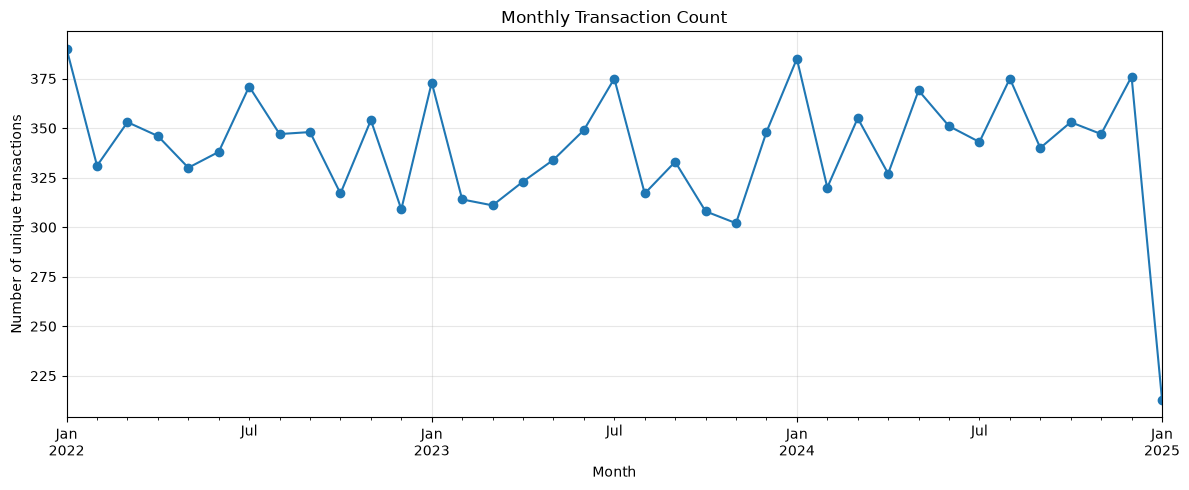

In [122]:
mon_transaction.plot(figsize=(12, 5), marker='o')
plt.xlabel('Month')
plt.ylabel('Number of unique transactions')
plt.title('Monthly Transaction Count')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [123]:
monthly_summary = pd.DataFrame({
    'Monthly_Revenue': month_rev,
    'Transaction': mon_transaction,
})
monthly_summary['Average_Revenue_per_Transaction'] = (
    monthly_summary['Monthly_Revenue'] / monthly_summary['Transaction'].replace(0, np.nan)
)
monthly_summary

,Monthly_Revenue,Transaction,Average_Revenue_per_Transaction
year_month,,,
2022-01,52911.5,390,135.670513
2022-02,43325.5,331,130.892749
2022-03,40996.0,353,116.135977
2022-04,40442.0,346,116.884393
2022-05,40347.5,330,122.265152
2022-06,42576.0,338,125.964497
2022-07,44471.5,371,119.869272
2022-08,41333.5,347,119.116715
2022-09,46113.5,348,132.510057


In [124]:
monthly_summary

,Monthly_Revenue,Transaction,Average_Revenue_per_Transaction
year_month,,,
2022-01,52911.5,390,135.670513
2022-02,43325.5,331,130.892749
2022-03,40996.0,353,116.135977
2022-04,40442.0,346,116.884393
2022-05,40347.5,330,122.265152
2022-06,42576.0,338,125.964497
2022-07,44471.5,371,119.869272
2022-08,41333.5,347,119.116715
2022-09,46113.5,348,132.510057


In [125]:
# calculate Month Over Month Growth
monthly_summary['Revenue_Growth_%']=monthly_summary['Monthly_Revenue'].pct_change()*100

In [126]:
monthly_summary

,Monthly_Revenue,Transaction,Average_Revenue_per_Transaction,Revenue_Growth_%
year_month,,,,
2022-01,52911.5,390,135.670513,NaN
2022-02,43325.5,331,130.892749,-18.117044
2022-03,40996.0,353,116.135977,-5.376741
2022-04,40442.0,346,116.884393,-1.351351
2022-05,40347.5,330,122.265152,-0.233668
2022-06,42576.0,338,125.964497,5.523267
2022-07,44471.5,371,119.869272,4.452039
2022-08,41333.5,347,119.116715,-7.056205
2022-09,46113.5,348,132.510057,11.564469


# Visualize Month Over Change

In [127]:
monthly_summary['Revenue_Growth_%']

year_month
2022-01          NaN
2022-02   -18.117044
2022-03    -5.376741
2022-04    -1.351351
2022-05    -0.233668
2022-06     5.523267
2022-07     4.452039
2022-08    -7.056205
2022-09    11.564469
2022-10   -16.824791
2022-11     7.564855
2022-12    -7.406106
2023-01    25.788592
2023-02   -18.392383
2023-03    -1.734052
2023-04     0.962774
2023-05     4.048271
2023-06     4.924593
2023-07     7.436314
2023-08   -15.428697
2023-09     6.418429
2023-10    -6.688743
2023-11    -3.413183
2023-12    16.228994
2024-01    11.360731
2024-02   -22.466786
2024-03    15.389689
2024-04     7.954691
2024-05    -5.412677
2024-06     2.180892
2024-07    -7.414861
2024-08     4.726482
2024-09    -2.768553
2024-10     1.363803
2024-11     3.134323
2024-12     9.961203
2025-01   -47.286270
Freq: M, Name: Revenue_Growth_%, dtype: float64

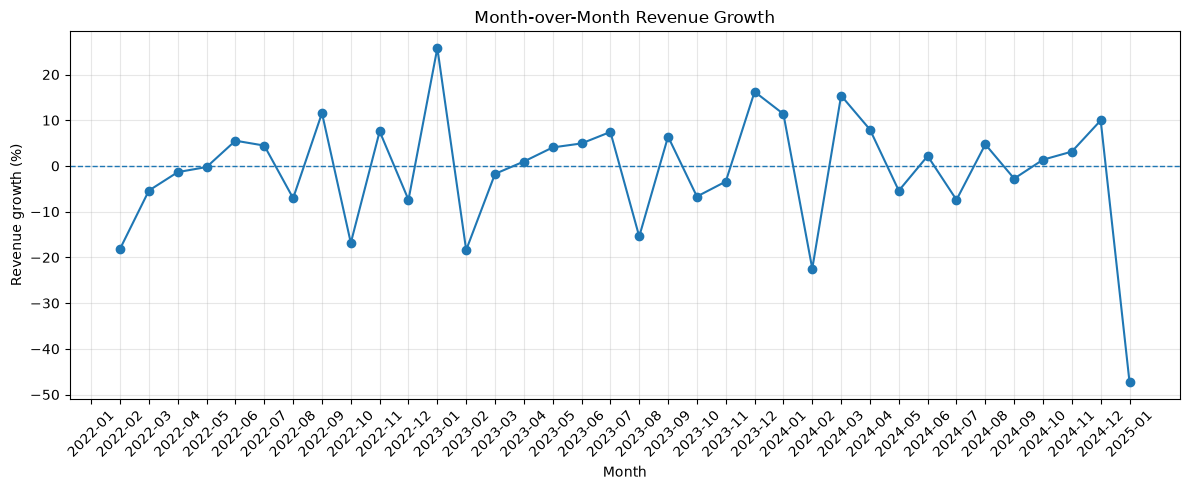

In [128]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_summary.index.astype(str), monthly_summary['Revenue_Growth_%'], marker='o')
plt.axhline(y=0, linestyle='--', linewidth=1)
plt.xlabel('Month')
plt.ylabel('Revenue growth (%)')
plt.title('Month-over-Month Revenue Growth')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Monthly Quantity Analysis

In [129]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [130]:
quant_month = df.groupby('year_month')['Quantity'].sum(min_count=1).sort_index()
quant_month

year_month
2022-01    2158.0
2022-02    1817.0
2022-03    1808.0
2022-04    1807.0
2022-05    1726.0
2022-06    1818.0
2022-07    1913.0
2022-08    1850.0
2022-09    1882.0
2022-10    1707.0
2022-11    1771.0
2022-12    1639.0
2023-01    2100.0
2023-02    1668.0
2023-03    1661.0
2023-04    1635.0
2023-05    1749.0
2023-06    1863.0
2023-07    1940.0
2023-08    1647.0
2023-09    1753.0
2023-10    1641.0
2023-11    1599.0
2023-12    1790.0
2024-01    2007.0
2024-02    1630.0
2024-03    1837.0
2024-04    1867.0
2024-05    1874.0
2024-06    1875.0
2024-07    1855.0
2024-08    1854.0
2024-09    1739.0
2024-10    1815.0
2024-11    1797.0
2024-12    2094.0
2025-01    1090.0
Freq: M, Name: Quantity, dtype: float64

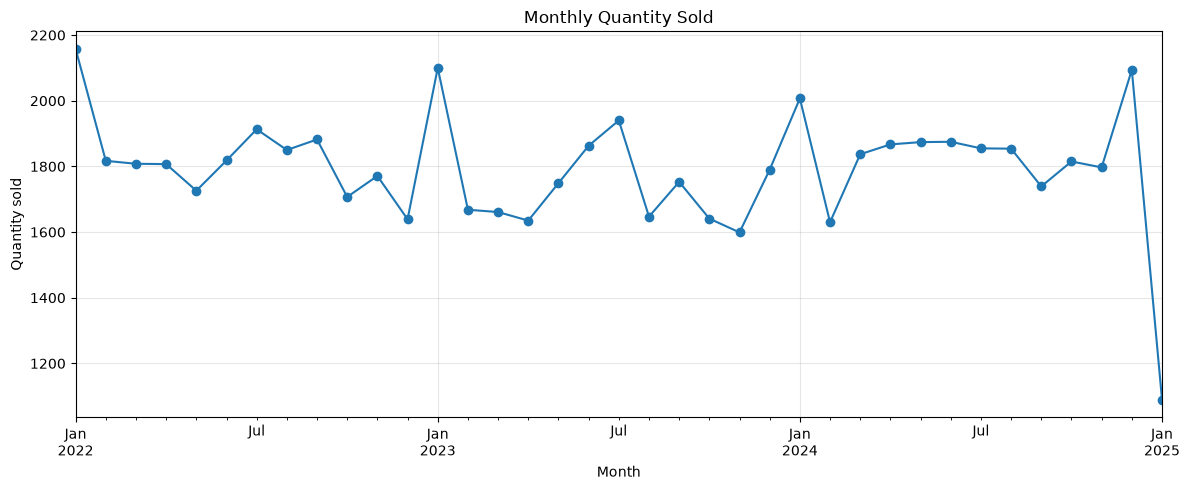

In [131]:
quant_month.plot(figsize=(12, 5), marker='o')
plt.xlabel('Month')
plt.ylabel('Quantity sold')
plt.title('Monthly Quantity Sold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [132]:
monthly_sales = pd.DataFrame({
    'Monthly_Revenue': month_rev,
    'Monthly_Quantity': quant_month
})
monthly_sales

,Monthly_Revenue,Monthly_Quantity
year_month,,
2022-01,52911.5,2158.0
2022-02,43325.5,1817.0
2022-03,40996.0,1808.0
2022-04,40442.0,1807.0
2022-05,40347.5,1726.0
2022-06,42576.0,1818.0
2022-07,44471.5,1913.0
2022-08,41333.5,1850.0
2022-09,46113.5,1882.0


# Quantity Vs TotalSpent
## scatterplot

In [133]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

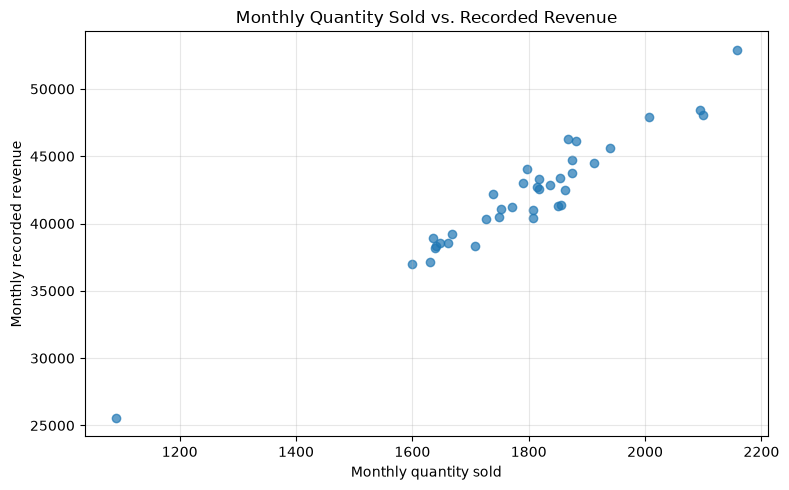

In [134]:
plt.figure(figsize=(8, 5))
plt.scatter(monthly_sales['Monthly_Quantity'], monthly_sales['Monthly_Revenue'], alpha=0.7)
plt.xlabel('Monthly quantity sold')
plt.ylabel('Monthly recorded revenue')
plt.title('Monthly Quantity Sold vs. Recorded Revenue')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [135]:
monthly_corr = monthly_sales[['Monthly_Revenue', 'Monthly_Quantity']].corr()
monthly_corr

,Monthly_Revenue,Monthly_Quantity
Monthly_Revenue,1.000000,0.967361
Monthly_Quantity,0.967361,1.000000


# correlation Heatmap

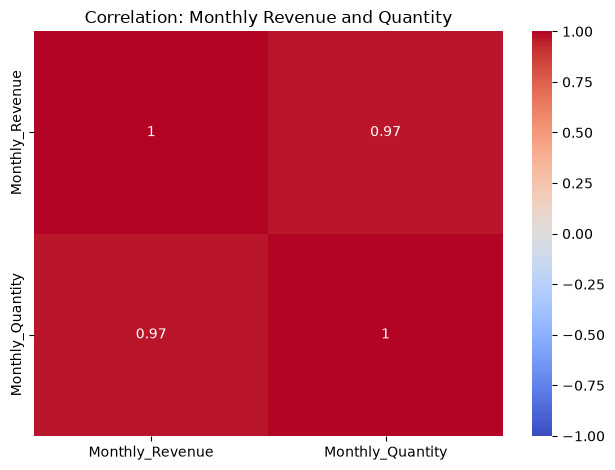

In [136]:
sns.heatmap(monthly_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation: Monthly Revenue and Quantity')
plt.tight_layout()
plt.show()

# Why Does Average Spending Differ by Category?

In [137]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [138]:
category_summary = df.groupby('Category').agg(
    Average_Unit_Price=('Price Per Unit', 'mean'),
    Average_Quantity=('Quantity', 'mean'),
    Average_Transaction_Revenue=('Revenue', 'mean'),
    Total_Revenue=('Revenue', lambda s: s.sum(min_count=1))
).sort_values('Total_Revenue', ascending=False)
category_summary

,Average_Unit_Price,Average_Quantity,Average_Transaction_Revenue,Total_Revenue
Category,,,,
Butchers,25.107462,5.485294,139.116310,208118.0
Electric household essentials,24.537712,5.480871,134.441623,203813.5
Beverages,23.290045,5.586898,131.716243,197047.5
Furniture,23.342238,5.548852,128.072131,195310.0
Food,23.075567,5.565362,129.271400,194812.0
Computers and electric accessories,23.114570,5.600542,129.107989,190692.5
Patisserie,23.072644,5.512144,126.416031,182165.5
Milk Products,21.411932,5.511566,119.042961,180112.0


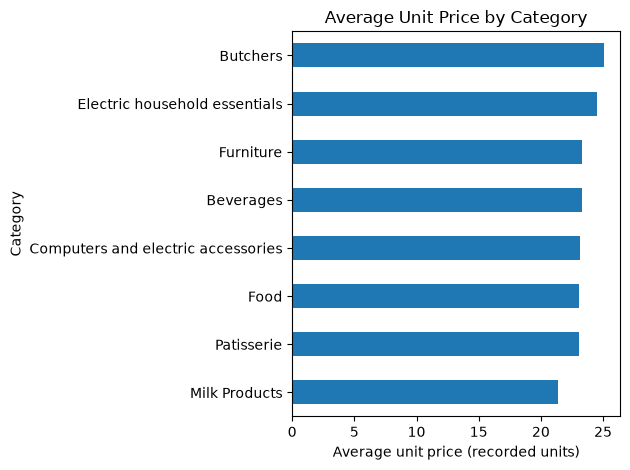

In [139]:
category_summary['Average_Unit_Price'].sort_values().plot(kind='barh')
plt.xlabel('Average unit price (recorded units)')
plt.ylabel('Category')
plt.title('Average Unit Price by Category')
plt.tight_layout()
plt.show()

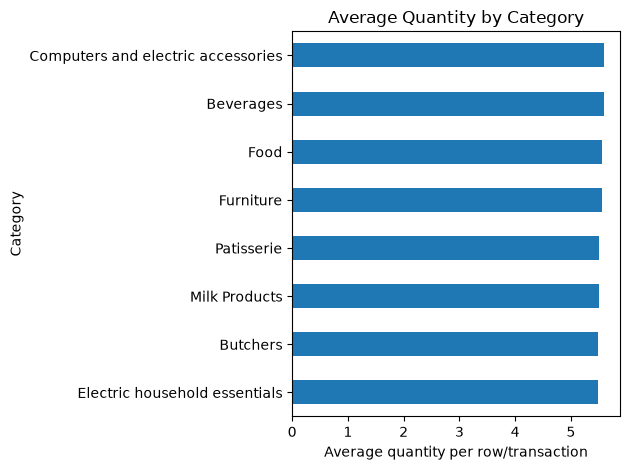

In [140]:
category_summary['Average_Quantity'].sort_values().plot(kind='barh')
plt.xlabel('Average quantity per row/transaction')
plt.ylabel('Category')
plt.title('Average Quantity by Category')
plt.tight_layout()
plt.show()

# Identify Best-Selling Products by Quantity

In [141]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [142]:
item_quant = df.groupby('Item')['Quantity'].sum(min_count=1).sort_values(ascending=False).head(10)
item_quant

Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64

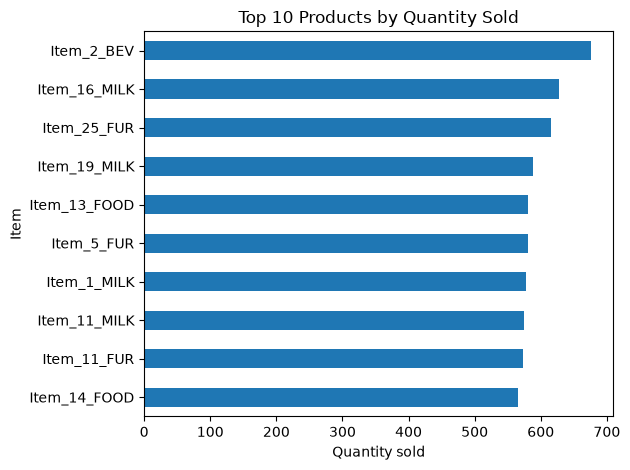

In [143]:
item_quant.sort_values().plot(kind='barh')
plt.xlabel('Quantity sold')
plt.ylabel('Item')
plt.title('Top 10 Products by Quantity Sold')
plt.tight_layout()
plt.show()

# Identify Products Generating the Highest Revenue

In [144]:
item_total = df.groupby('Item')['Revenue'].sum(min_count=1).sort_values(ascending=False).head(10)
item_total

Item
Item_25_FUR     25256.0
Item_25_EHE     23083.0
Item_25_BUT     21894.0
Item_24_FUR     21172.0
Item_25_FOOD    20541.0
Item_22_BUT     19710.0
Item_23_BUT     19114.0
Item_20_BUT     18860.5
Item_19_MILK    18848.0
Item_23_EHE     18468.0
Name: Revenue, dtype: float64

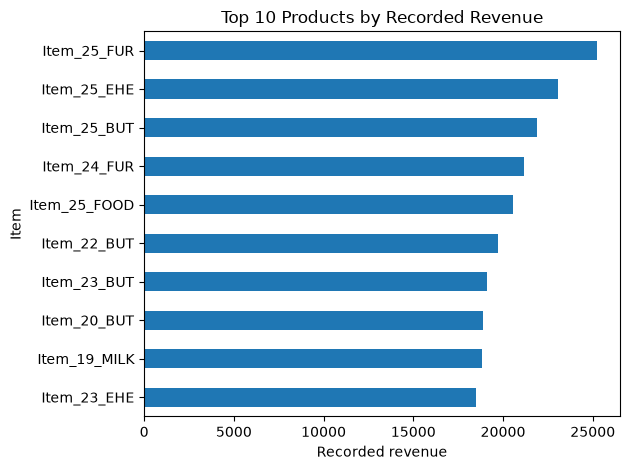

In [145]:
item_total.sort_values().plot(kind='barh')
plt.xlabel('Recorded revenue')
plt.ylabel('Item')
plt.title('Top 10 Products by Recorded Revenue')
plt.tight_layout()
plt.show()

In [146]:
product_performance = df.groupby('Item').agg(
    Total_Revenue=('Revenue', lambda s: s.sum(min_count=1)),
    Product_Quantity=('Quantity', lambda s: s.sum(min_count=1))
).sort_values('Total_Revenue', ascending=False)
product_performance.head(10)

,Total_Revenue,Product_Quantity
Item,,
Item_25_FUR,25256.0,616.0
Item_25_EHE,23083.0,563.0
Item_25_BUT,21894.0,534.0
Item_24_FUR,21172.0,536.0
Item_25_FOOD,20541.0,501.0
Item_22_BUT,19710.0,540.0
Item_23_BUT,19114.0,503.0
Item_20_BUT,18860.5,563.0
Item_19_MILK,18848.0,589.0


# (or)

In [147]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [148]:
product_performance = df.groupby('Item').agg(
    Total_Revenue=('Revenue', lambda s: s.sum(min_count=1)),
    Product_Quantity=('Quantity', lambda s: s.sum(min_count=1))
)
product_performance

,Total_Revenue,Product_Quantity
Item,,
Item_10_BEV,2886.0,156.0
Item_10_BUT,1739.0,94.0
Item_10_CEA,7252.0,392.0
Item_10_EHE,3811.0,206.0
Item_10_FOOD,5291.0,286.0
...,...,...
Item_9_EHE,5933.0,349.0
Item_9_FOOD,7072.0,416.0
Item_9_FUR,1360.0,80.0


In [149]:
product_performance.sort_values(by='Total_Revenue', ascending=False).head()

,Total_Revenue,Product_Quantity
Item,,
Item_25_FUR,25256.0,616.0
Item_25_EHE,23083.0,563.0
Item_25_BUT,21894.0,534.0
Item_24_FUR,21172.0,536.0
Item_25_FOOD,20541.0,501.0


# Visualize quantity sold versus revenue

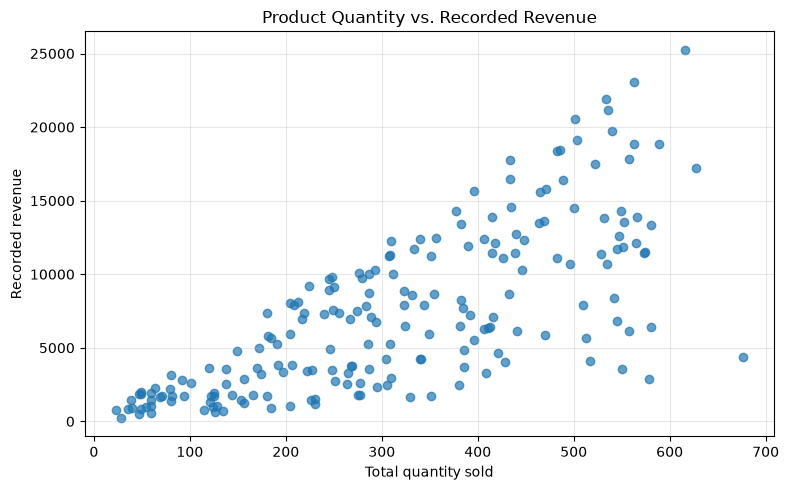

In [150]:
plt.figure(figsize=(8, 5))
plt.scatter(product_performance['Product_Quantity'], product_performance['Total_Revenue'], alpha=0.7)
plt.xlabel('Total quantity sold')
plt.ylabel('Recorded revenue')
plt.title('Product Quantity vs. Recorded Revenue')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [151]:
product_performance[['Total_Revenue', 'Product_Quantity']].corr()

,Total_Revenue,Product_Quantity
Total_Revenue,1.000000,0.734402
Product_Quantity,0.734402,1.000000


# Pareto Analysis (80/20 Rule)
## Do a small number of products generate a large percentage of total revenue?
The Pareto principle, often called the 80/20 rule, suggests that a large share of results may come from a relatively small share of causes.
For example, 20% of products might generate 80% of revenue. Your dataset may show a different pattern—we need to calculate it.

In [152]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [153]:
item_total = df.groupby('Item')['Revenue'].sum(min_count=1).dropna().sort_values(ascending=False)
item_total

Item
Item_25_FUR     25256.0
Item_25_EHE     23083.0
Item_25_BUT     21894.0
Item_24_FUR     21172.0
Item_25_FOOD    20541.0
                 ...   
Item_1_FOOD       675.0
Item_1_CEA        630.0
Item_4_CEA        570.0
Item_5_BEV        517.0
Item_3_EHE        224.0
Name: Revenue, Length: 200, dtype: float64

In [154]:
total_rev_items = item_total.sum()
item_total_percentage = item_total / total_rev_items * 100
item_total_cum_percentage = item_total_percentage.cumsum()
item_total_percentage

Item
Item_25_FUR     1.714598
Item_25_EHE     1.567076
Item_25_BUT     1.486356
Item_24_FUR     1.437340
Item_25_FOOD    1.394502
                  ...   
Item_1_FOOD     0.045825
Item_1_CEA      0.042770
Item_4_CEA      0.038697
Item_5_BEV      0.035098
Item_3_EHE      0.015207
Name: Revenue, Length: 200, dtype: float64

In [155]:
pareto_analysis = pd.DataFrame({
    'Item_Revenue': item_total,
    'Revenue_Percentage': item_total_percentage,
    'Cumulative_Revenue_Percentage': item_total_cum_percentage
})
pareto_analysis

,Item_Revenue,Revenue_Percentage,Cumulative_Revenue_Percentage
Item,,,
Item_25_FUR,25256.0,1.714598,1.714598
Item_25_EHE,23083.0,1.567076,3.281673
Item_25_BUT,21894.0,1.486356,4.768029
Item_24_FUR,21172.0,1.437340,6.205370
Item_25_FOOD,20541.0,1.394502,7.599872
...,...,...,...
Item_1_FOOD,675.0,0.045825,99.868228
Item_1_CEA,630.0,0.042770,99.910998
Item_4_CEA,570.0,0.038697,99.949694


# Visualize the cumulative contribution

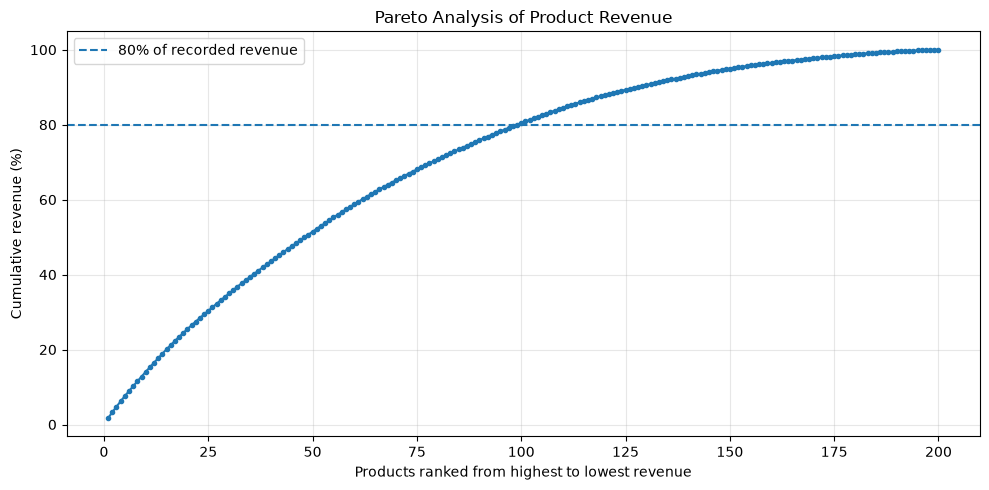

In [156]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(pareto_analysis) + 1), pareto_analysis['Cumulative_Revenue_Percentage'], marker='.')
plt.axhline(y=80, linestyle='--', label='80% of recorded revenue')
plt.xlabel('Products ranked from highest to lowest revenue')
plt.ylabel('Cumulative revenue (%)')
plt.title('Pareto Analysis of Product Revenue')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Find how many customers contribute 80% of revenue

In [157]:
products_needed_80 = int((pareto_analysis['Cumulative_Revenue_Percentage'] < 80).sum())
# Include the product that first takes cumulative contribution to 80% or above.
products_needed_80 = min(products_needed_80 + 1, len(pareto_analysis)) if len(pareto_analysis) else 0
print('Products needed to reach at least 80% of recorded revenue:', products_needed_80)
print('Total products with recorded revenue:', len(pareto_analysis))

Products needed to reach at least 80% of recorded revenue: 99
Total products with recorded revenue: 200


# Customer Revenue Concentration

In [158]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [159]:
cust_rev = df.groupby('Customer ID')['Revenue'].sum(min_count=1).dropna().sort_values(ascending=False)
cust_rev

Customer ID
CUST_24    68452.0
CUST_08    67351.5
CUST_05    66974.5
CUST_16    65570.5
CUST_13    65037.0
CUST_23    64507.0
CUST_10    63155.5
CUST_15    63117.5
CUST_21    62933.0
CUST_02    62046.5
CUST_04    61767.5
CUST_22    61732.5
CUST_20    61533.0
CUST_09    61423.5
CUST_12    61360.0
CUST_03    60811.0
CUST_19    60797.0
CUST_11    60733.0
CUST_07    60694.5
CUST_14    60528.0
CUST_18    59142.0
CUST_01    58731.5
CUST_06    58632.5
CUST_17    57884.5
CUST_25    57155.5
Name: Revenue, dtype: float64

In [160]:
cust_rev_total = cust_rev.sum()
cust_rev_total_percent = cust_rev / cust_rev_total * 100
cust_rev_total_percent

Customer ID
CUST_24    4.410365
CUST_08    4.339460
CUST_05    4.315170
CUST_16    4.224710
CUST_13    4.190337
CUST_23    4.156189
CUST_10    4.069112
CUST_15    4.066663
CUST_21    4.054776
CUST_02    3.997659
CUST_04    3.979683
CUST_22    3.977428
CUST_20    3.964574
CUST_09    3.957519
CUST_12    3.953427
CUST_03    3.918055
CUST_19    3.917153
CUST_11    3.913030
CUST_07    3.910549
CUST_14    3.899822
CUST_18    3.810522
CUST_01    3.784073
CUST_06    3.777694
CUST_17    3.729501
CUST_25    3.682531
Name: Revenue, dtype: float64

In [161]:
cust_rev_total_percent_cum = cust_rev_total_percent.cumsum()
cust_rev_total_percent_cum

Customer ID
CUST_24      4.410365
CUST_08      8.749825
CUST_05     13.064995
CUST_16     17.289705
CUST_13     21.480042
CUST_23     25.636231
CUST_10     29.705342
CUST_15     33.772005
CUST_21     37.826781
CUST_02     41.824440
CUST_04     45.804122
CUST_22     49.781550
CUST_20     53.746124
CUST_09     57.703642
CUST_12     61.657070
CUST_03     65.575125
CUST_19     69.492278
CUST_11     73.405308
CUST_07     77.315857
CUST_14     81.215679
CUST_18     85.026200
CUST_01     88.810273
CUST_06     92.587968
CUST_17     96.317469
CUST_25    100.000000
Name: Revenue, dtype: float64

In [162]:
cust_concentration_analysis = pd.DataFrame({
    'Customer_Revenue': cust_rev,
    'Revenue_Percentage': cust_rev_total_percent,
    'Cumulative_Revenue_Percentage': cust_rev_total_percent_cum
})

In [163]:
cust_concentration_analysis

,Customer_Revenue,Revenue_Percentage,Cumulative_Revenue_Percentage
Customer ID,,,
CUST_24,68452.0,4.410365,4.410365
CUST_08,67351.5,4.339460,8.749825
CUST_05,66974.5,4.315170,13.064995
CUST_16,65570.5,4.224710,17.289705
CUST_13,65037.0,4.190337,21.480042
CUST_23,64507.0,4.156189,25.636231
CUST_10,63155.5,4.069112,29.705342
CUST_15,63117.5,4.066663,33.772005
CUST_21,62933.0,4.054776,37.826781


In [164]:
customers_needed = int((cust_concentration_analysis['Cumulative_Revenue_Percentage'] < 80).sum())
customers_needed = min(customers_needed + 1, len(cust_concentration_analysis)) if len(cust_concentration_analysis) else 0
total_customers_with_revenue = len(cust_concentration_analysis)
customer_percentage = customers_needed / total_customers_with_revenue * 100 if total_customers_with_revenue else np.nan

In [165]:
print('Customers needed to reach at least 80% of recorded revenue:', customers_needed)
print('Customers with recorded revenue:', total_customers_with_revenue)
print(f'Percentage of customers: {customer_percentage:.2f}%')

Customers needed to reach at least 80% of recorded revenue: 20
Customers with recorded revenue: 25
Percentage of customers: 80.00%


# Customer Purchase Frequency vs. Total Spending

In [166]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [167]:
customer_behaviour = df.groupby('Customer ID').agg(
    Purchase_Frequency=('Transaction ID', 'nunique'),
    Total_Spend=('Revenue', lambda s: s.sum(min_count=1))
)
customer_behaviour.head()

,Purchase_Frequency,Total_Spend
Customer ID,,
CUST_01,507,58731.5
CUST_02,488,62046.5
CUST_03,465,60811.0
CUST_04,474,61767.5
CUST_05,544,66974.5


# Create a scatter plot using Matplotlib

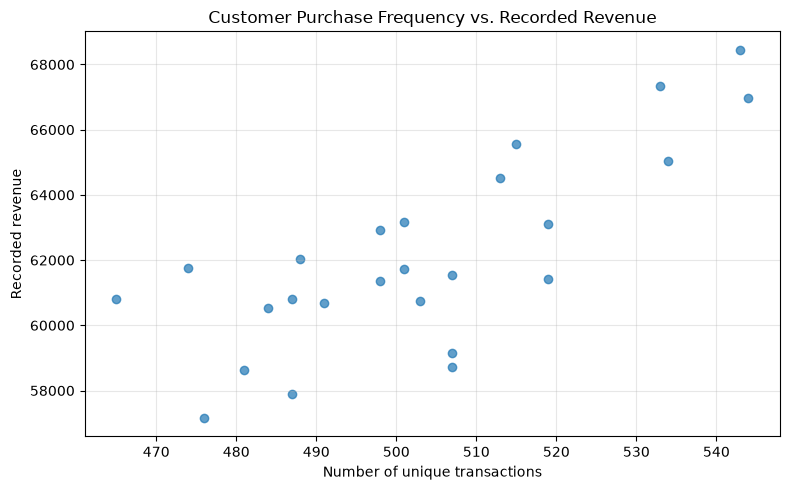

In [168]:
plt.figure(figsize=(8, 5))
plt.scatter(customer_behaviour['Purchase_Frequency'], customer_behaviour['Total_Spend'], alpha=0.7)
plt.xlabel('Number of unique transactions')
plt.ylabel('Recorded revenue')
plt.title('Customer Purchase Frequency vs. Recorded Revenue')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [169]:
customer_behaviour[['Purchase_Frequency', 'Total_Spend']].corr()

,Purchase_Frequency,Total_Spend
Purchase_Frequency,1.000000,0.770937
Total_Spend,0.770937,1.000000


# Customer Spending Segmentation

In [170]:
low_threshold = customer_behaviour['Total_Spend'].quantile(0.33)
high_threshold = customer_behaviour['Total_Spend'].quantile(0.66)
customer_behaviour['Customer_Segment'] = np.select(
    [
        customer_behaviour['Total_Spend'] <= low_threshold,
        (customer_behaviour['Total_Spend'] > low_threshold) & (customer_behaviour['Total_Spend'] <= high_threshold),
        customer_behaviour['Total_Spend'] > high_threshold,
    ],
    ['Low spending', 'Medium spending', 'High spending'],
    default='Unknown'
)
customer_behaviour['Customer_Segment']

Customer ID
CUST_01       Low spending
CUST_02    Medium spending
CUST_03    Medium spending
CUST_04    Medium spending
CUST_05      High spending
CUST_06       Low spending
CUST_07       Low spending
CUST_08      High spending
CUST_09    Medium spending
CUST_10      High spending
CUST_11       Low spending
CUST_12    Medium spending
CUST_13      High spending
CUST_14       Low spending
CUST_15      High spending
CUST_16      High spending
CUST_17       Low spending
CUST_18       Low spending
CUST_19    Medium spending
CUST_20    Medium spending
CUST_21      High spending
CUST_22    Medium spending
CUST_23      High spending
CUST_24      High spending
CUST_25       Low spending
Name: Customer_Segment, dtype: str

In [171]:
customer_behaviour.head()

,Purchase_Frequency,Total_Spend,Customer_Segment
Customer ID,,,
CUST_01,507,58731.5,Low spending
CUST_02,488,62046.5,Medium spending
CUST_03,465,60811.0,Medium spending
CUST_04,474,61767.5,Medium spending
CUST_05,544,66974.5,High spending


In [172]:
customer_behaviour.columns

Index(['Purchase_Frequency', 'Total_Spend', 'Customer_Segment'], dtype='str')

# Count customers in each segment

In [173]:
segment_count=customer_behaviour['Customer_Segment'].value_counts()

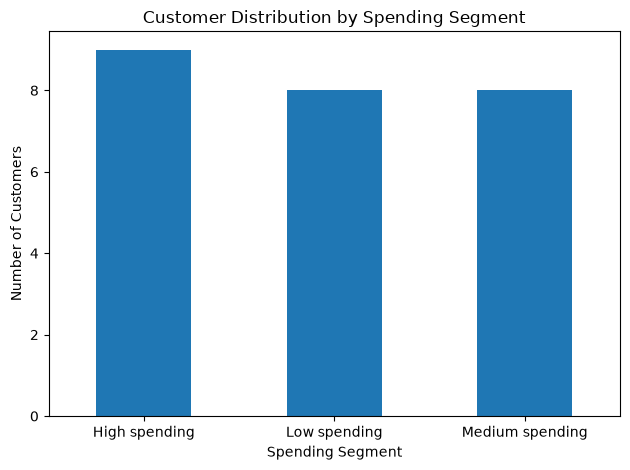

In [174]:
# visualize
segment_count.plot(kind='bar')

plt.xlabel('Spending Segment')
plt.ylabel('Number of Customers')
plt.title('Customer Distribution by Spending Segment')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Compare revenue across segments

In [175]:
customer_behaviour.columns

Index(['Purchase_Frequency', 'Total_Spend', 'Customer_Segment'], dtype='str')

In [176]:
customer_behaviour.groupby('Customer_Segment').agg(
    Customer_Count=('Purchase_Frequency', 'count'),
    Total_Revenue=('Total_Spend', 'sum'),
    Average_Customer_Spending=('Total_Spend', 'mean')
).sort_values('Total_Revenue', ascending=False)

,Customer_Count,Total_Revenue,Average_Customer_Spending
Customer_Segment,,,
High spending,9,587098.5,65233.166667
Medium spending,8,491471.0,61433.875000
Low spending,8,473501.5,59187.687500


# Customer Retention Analysis

In [177]:
df.dtypes

Transaction ID                      str
Customer ID                         str
Category                            str
Item                                str
Price Per Unit                  float64
Quantity                        float64
Total Spent                     float64
Payment Method                      str
Location                            str
Transaction Date         datetime64[us]
Discount Applied                 object
Calculated Unit Price           float64
Revenue                         float64
year_month                    period[M]
dtype: object

In [178]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

# Count the distinct months in which each customer purchased

In [179]:
customer_months = df.groupby('Customer ID')['year_month'].nunique()
customer_months

Customer ID
CUST_01    37
CUST_02    37
CUST_03    37
CUST_04    37
CUST_05    37
CUST_06    37
CUST_07    37
CUST_08    37
CUST_09    37
CUST_10    37
CUST_11    37
CUST_12    37
CUST_13    37
CUST_14    37
CUST_15    37
CUST_16    37
CUST_17    37
CUST_18    37
CUST_19    37
CUST_20    37
CUST_21    37
CUST_22    37
CUST_23    37
CUST_24    37
CUST_25    37
Name: year_month, dtype: int64

# Classify customers by repeat-month activity

In [180]:
customer_retention = pd.DataFrame({'Active_Months': customer_months})
customer_retention['Customer_Type'] = np.where(
    customer_retention['Active_Months'] > 1,
    'Multi-Month Customer',
    'Single-Month Customer'
)
customer_retention

,Active_Months,Customer_Type
Customer ID,,
CUST_01,37,Multi-Month Customer
CUST_02,37,Multi-Month Customer
CUST_03,37,Multi-Month Customer
CUST_04,37,Multi-Month Customer
CUST_05,37,Multi-Month Customer
CUST_06,37,Multi-Month Customer
CUST_07,37,Multi-Month Customer
CUST_08,37,Multi-Month Customer
CUST_09,37,Multi-Month Customer


In [181]:
customer_retention.head()

,Active_Months,Customer_Type
Customer ID,,
CUST_01,37,Multi-Month Customer
CUST_02,37,Multi-Month Customer
CUST_03,37,Multi-Month Customer
CUST_04,37,Multi-Month Customer
CUST_05,37,Multi-Month Customer


# Calculate the customer distribution

In [182]:
cust_dist=customer_retention['Customer_Type'].value_counts()

In [183]:
# Calculate the percentages
cust_dist_Percent=customer_retention['Customer_Type'].value_counts(normalize=True).mul(100)
cust_dist_Percent

Customer_Type
Multi-Month Customer    100.0
Name: proportion, dtype: float64

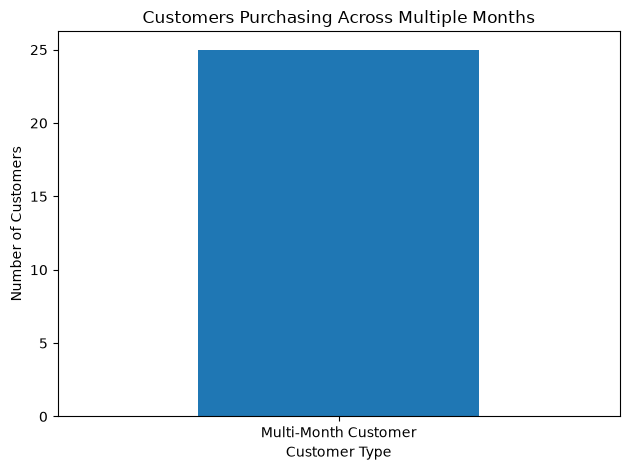

In [184]:
# visualize
cust_dist.plot(kind='bar')

plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')
plt.title('Customers Purchasing Across Multiple Months')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Monthly Active Customer Analysis

In [185]:
# Count unique customers per month
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [186]:
active_month = df.groupby('year_month')['Customer ID'].nunique().sort_index()

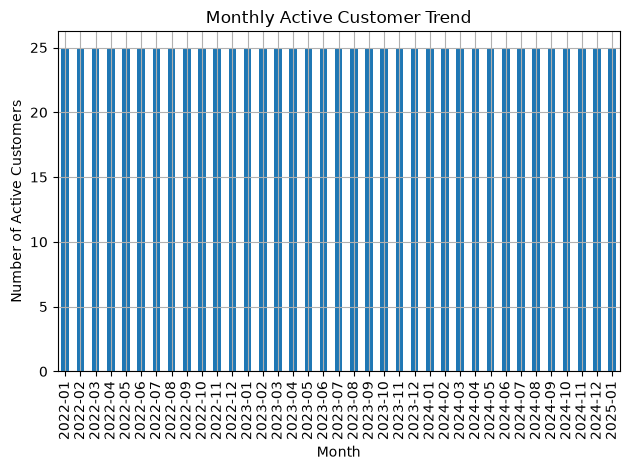

In [187]:
# Visualize monthly active customers
active_month.plot(kind='bar')

plt.xlabel('Month')
plt.ylabel('Number of Active Customers')
plt.title('Monthly Active Customer Trend')

plt.grid()
plt.tight_layout()
plt.show()

# Calculate month-over-month customer growth

In [188]:
monthly_customer_growth=active_month.pct_change()*100
monthly_customer_growth

year_month
2022-01    NaN
2022-02    0.0
2022-03    0.0
2022-04    0.0
2022-05    0.0
2022-06    0.0
2022-07    0.0
2022-08    0.0
2022-09    0.0
2022-10    0.0
2022-11    0.0
2022-12    0.0
2023-01    0.0
2023-02    0.0
2023-03    0.0
2023-04    0.0
2023-05    0.0
2023-06    0.0
2023-07    0.0
2023-08    0.0
2023-09    0.0
2023-10    0.0
2023-11    0.0
2023-12    0.0
2024-01    0.0
2024-02    0.0
2024-03    0.0
2024-04    0.0
2024-05    0.0
2024-06    0.0
2024-07    0.0
2024-08    0.0
2024-09    0.0
2024-10    0.0
2024-11    0.0
2024-12    0.0
2025-01    0.0
Freq: M, Name: Customer ID, dtype: float64

# Monthly Revenue vs. Active Customers

In [189]:
monthly_rev = df.groupby('year_month')['Revenue'].sum(min_count=1).sort_index()
monthly_rev.head()

year_month
2022-01    52911.5
2022-02    43325.5
2022-03    40996.0
2022-04    40442.0
2022-05    40347.5
Freq: M, Name: Revenue, dtype: float64

In [190]:
# Combine revenue and cufrstomer counts
monthly_business=pd.DataFrame(
    {
     'monthly_rev':monthly_rev,
     'active_cust':active_month
})
monthly_business.head()

,monthly_rev,active_cust
year_month,,
2022-01,52911.5,25
2022-02,43325.5,25
2022-03,40996.0,25
2022-04,40442.0,25
2022-05,40347.5,25


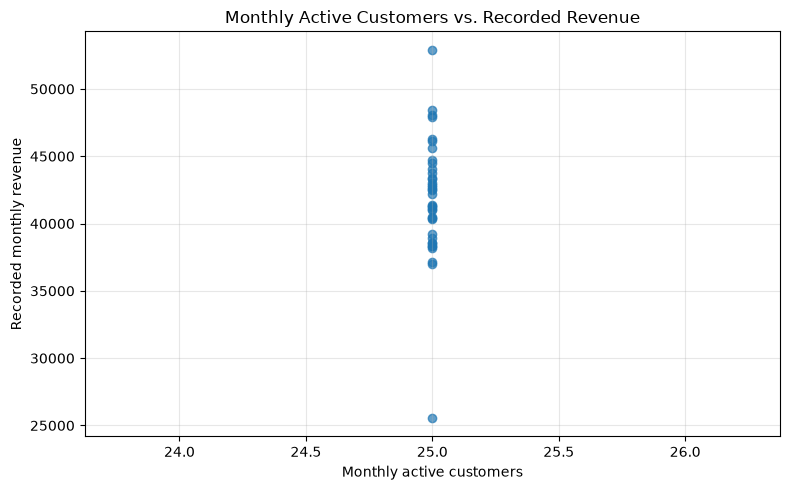

In [191]:
plt.figure(figsize=(8, 5))
plt.scatter(monthly_business['active_cust'], monthly_business['monthly_rev'], alpha=0.7)
plt.xlabel('Monthly active customers')
plt.ylabel('Recorded monthly revenue')
plt.title('Monthly Active Customers vs. Recorded Revenue')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [192]:
# If active-customer counts are identical across months, their correlation is undefined (NaN).
monthly_business_corr = monthly_business[['monthly_rev', 'active_cust']].corr()
monthly_business_corr

,monthly_rev,active_cust
monthly_rev,1.0,NaN
active_cust,NaN,NaN


# Average Revenue per Transaction by Month 

In [193]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [194]:
month_transaction = df.groupby('year_month')['Transaction ID'].nunique().sort_index()

In [195]:
monthly_rev.head()

year_month
2022-01    52911.5
2022-02    43325.5
2022-03    40996.0
2022-04    40442.0
2022-05    40347.5
Freq: M, Name: Revenue, dtype: float64

In [196]:
monthly_transaction_analysis = pd.DataFrame({
    'Transaction_Count': month_transaction,
    'Monthly_Revenue': monthly_rev
})
monthly_transaction_analysis.head(20)

,Transaction_Count,Monthly_Revenue
year_month,,
2022-01,390,52911.5
2022-02,331,43325.5
2022-03,353,40996.0
2022-04,346,40442.0
2022-05,330,40347.5
2022-06,338,42576.0
2022-07,371,44471.5
2022-08,347,41333.5
2022-09,348,46113.5


In [197]:
monthly_transaction_analysis['Average_Revenue_per_Transaction'] = (
    monthly_transaction_analysis['Monthly_Revenue'] /
    monthly_transaction_analysis['Transaction_Count'].replace(0, np.nan)
)

In [198]:
monthly_transaction_analysis.head()

,Transaction_Count,Monthly_Revenue,Average_Revenue_per_Transaction
year_month,,,
2022-01,390,52911.5,135.670513
2022-02,331,43325.5,130.892749
2022-03,353,40996.0,116.135977
2022-04,346,40442.0,116.884393
2022-05,330,40347.5,122.265152


# Business Performance Summary Dashboard
## How is the retail business performing overall?
1. Calculate the key business metrics
We'll calculate:
- Total recorded revenue
- Number of unique transactions
- Number of unique customers
- Average revenue per transaction
- Total recorded quantity sold

In [199]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

In [200]:
total_rev = df['Revenue'].sum(min_count=1)
total_transaction = df['Transaction ID'].nunique()
total_customer = df['Customer ID'].nunique()
total_quantity = df['Quantity'].sum(min_count=1)
average_revenue_per_transaction = total_rev / total_transaction if total_transaction > 0 else np.nan

# Create a business summary table

In [201]:
business_summary = pd.DataFrame({
    'Metric': [
        'Total Recorded Revenue',
        'Total Unique Transactions',
        'Total Unique Customers',
        'Total Recorded Quantity',
        'Average Revenue per Transaction'
    ],
    'Value': [
        total_rev,
        total_transaction,
        total_customer,
        total_quantity,
        average_revenue_per_transaction
    ]
})
business_summary

,Metric,Value
0,Total Recorded Revenue,1.552071e+06
1,Total Unique Transactions,1.257500e+04
2,Total Unique Customers,2.500000e+01
3,Total Recorded Quantity,6.627600e+04
4,Average Revenue per Transaction,1.234251e+02


# Format the results for presentation

In [202]:
business_summary['Value'] = business_summary.apply(
    lambda row: f"{row['Value']:,.2f}" if pd.notna(row['Value']) else 'Not available',
    axis=1
)

In [203]:
business_summary

,Metric,Value
0,Total Recorded Revenue,"1,552,071.00"
1,Total Unique Transactions,"12,575.00"
2,Total Unique Customers,25.00
3,Total Recorded Quantity,"66,276.00"
4,Average Revenue per Transaction,123.43


# Build a Business Dashboard with Multiple Charts
Business question
Can a business manager understand retail performance quickly from a single dashboard?
We'll display:
1. Revenue by product category.
2. Monthly revenue trend.
3. Customer distribution by spending segment.

In [204]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied', 'Calculated Unit Price',
       'Revenue', 'year_month'],
      dtype='str')

## Chart 1: Revenue by category

In [205]:
cat_rev=df.groupby('Category')['Revenue'].sum(min_count=1).sort_values(ascending=False)
cat_rev

Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Revenue, dtype: float64

## Chart 2: Monthly revenue trend

In [206]:
# Keep chronological order for a trend chart; do not sort months by revenue.
month_rev = df.groupby('year_month')['Revenue'].sum(min_count=1).sort_index()
month_rev.tail(12)

year_month
2024-02    37145.0
2024-03    42861.5
2024-04    46271.0
2024-05    43766.5
2024-06    44721.0
2024-07    41405.0
2024-08    43362.0
2024-09    42161.5
2024-10    42736.5
2024-11    44076.0
2024-12    48466.5
2025-01    25548.5
Freq: M, Name: Revenue, dtype: float64

## Chart 3: Customer spending segments

In [207]:
cust_spend=customer_behaviour['Customer_Segment'].value_counts()

# Create the dashboard

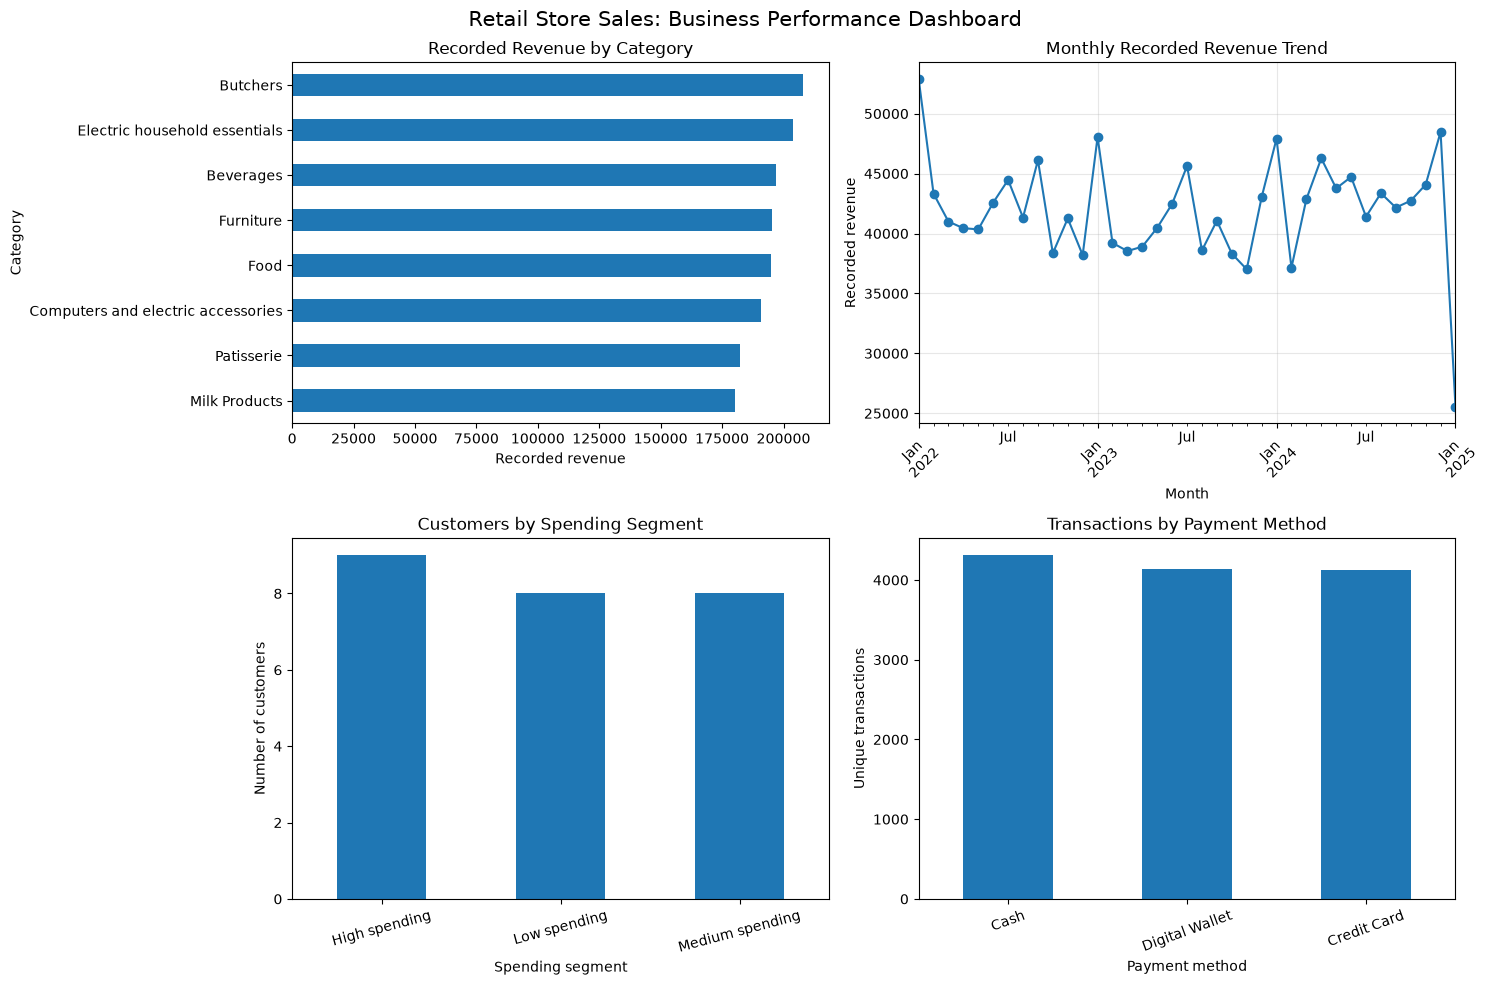

In [208]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Revenue by category
cat_rev = df.groupby('Category')['Revenue'].sum(min_count=1).sort_values(ascending=False)
cat_rev.sort_values().plot(kind='barh', ax=axes[0, 0])
axes[0, 0].set_title('Recorded Revenue by Category')
axes[0, 0].set_xlabel('Recorded revenue')
axes[0, 0].set_ylabel('Category')

# 2. Monthly revenue trend (chronological order)
month_rev.plot(ax=axes[0, 1], marker='o')
axes[0, 1].set_title('Monthly Recorded Revenue Trend')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Recorded revenue')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(alpha=0.3)

# 3. Customer spending segments
cust_spend = customer_behaviour['Customer_Segment'].value_counts()
cust_spend.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Customers by Spending Segment')
axes[1, 0].set_xlabel('Spending segment')
axes[1, 0].set_ylabel('Number of customers')
axes[1, 0].tick_params(axis='x', rotation=15)

# 4. Transaction count by payment method
payment_counts = df.groupby('Payment Method')['Transaction ID'].nunique().sort_values(ascending=False)
payment_counts.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Transactions by Payment Method')
axes[1, 1].set_xlabel('Payment method')
axes[1, 1].set_ylabel('Unique transactions')
axes[1, 1].tick_params(axis='x', rotation=20)

fig.suptitle('Retail Store Sales: Business Performance Dashboard', fontsize=15)
plt.tight_layout()
plt.show()

## 10. Final interpretation and publishing checklist

### A. Final interpretation

Run the summary cell below **after running the notebook from the first cell to the last**. Use its actual results to write 3–5 findings. Do not copy example values from tutorials or guess results.

For each finding, explain:
1. **Finding:** What does the data show?
2. **Evidence:** Which number, percentage, or chart supports it?
3. **Business meaning:** Why might it matter to the retailer?
4. **Caution:** What can this dataset not tell us?

Use cautious wording such as “is associated with” rather than claiming that one factor caused another. Revenue is described as **recorded revenue** because the source totals may not always reconcile with price × quantity.



In [209]:
# Final metrics to support your interpretation (values come from the loaded dataset)
required_columns = ['Revenue', 'Category', 'Item', 'Customer ID', 'Transaction ID']
missing_required = [col for col in required_columns if col not in df.columns]
if missing_required:
    print('Cannot calculate all final metrics. Missing columns:', missing_required)
else:
    recorded_revenue = df['Revenue'].sum(min_count=1)
    transaction_count = df['Transaction ID'].nunique()
    customer_count = df['Customer ID'].nunique()
    quantity_total = df['Quantity'].sum(min_count=1) if 'Quantity' in df.columns else np.nan

    print(f'Rows in dataset: {len(df):,}')
    print(f'Total recorded revenue: {recorded_revenue:,.2f}' if pd.notna(recorded_revenue) else 'Total recorded revenue: Not available')
    print(f'Unique transactions: {transaction_count:,}')
    print(f'Unique customers: {customer_count:,}')
    print(f'Total recorded quantity: {quantity_total:,.2f}' if pd.notna(quantity_total) else 'Total recorded quantity: Not available')

    category_revenue = df.groupby('Category')['Revenue'].sum(min_count=1).dropna().sort_values(ascending=False)
    item_revenue = df.groupby('Item')['Revenue'].sum(min_count=1).dropna().sort_values(ascending=False)
    if not category_revenue.empty:
        print('Top category by recorded revenue:', category_revenue.index[0], f'({category_revenue.iloc[0]:,.2f})')
    if not item_revenue.empty:
        print('Top item by recorded revenue:', item_revenue.index[0], f'({item_revenue.iloc[0]:,.2f})')

    if 'year_month' in df.columns:
        monthly_revenue = df.groupby('year_month')['Revenue'].sum(min_count=1).dropna().sort_index()
        if not monthly_revenue.empty:
            print('Highest recorded-revenue month:', monthly_revenue.idxmax(), f'({monthly_revenue.max():,.2f})')
            print('Lowest recorded-revenue month:', monthly_revenue.idxmin(), f'({monthly_revenue.min():,.2f})')


Rows in dataset: 12,575
Total recorded revenue: 1,552,071.00
Unique transactions: 12,575
Unique customers: 25
Total recorded quantity: 66,276.00
Top category by recorded revenue: Butchers (208,118.00)
Top item by recorded revenue: Item_25_FUR (25,256.00)
Highest recorded-revenue month: 2022-01 (52,911.50)
Lowest recorded-revenue month: 2025-01 (25,548.50)


## B. Final Findings

- **Sales Performance:** The dataset recorded a total revenue of 1,552,071.00 from 12,575 transactions, providing an overview of the business's overall sales performance.

- **Category Performance:** Butchers was the top-performing category, generating a recorded revenue of 208,118.00.

- **Product Performance:** Item_25_FUR generated the highest recorded revenue among all products, contributing 25,256.00 to total revenue.

- **Customer Behaviour:** The dataset contains 25 unique customers across 12,575 transactions. Analysing customer purchase frequency and spending patterns can help identify valuable and frequent customers.

- **Time Trend:** Monthly revenue varied throughout the observed period. January 2022 recorded the highest monthly revenue of 52,911.50, while January 2025 recorded the lowest monthly revenue of 25,548.50.
